In [1]:
import os
import glob

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import seaborn as sns

from sklearn.manifold import MDS

plt.style.use("default")

plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 11

sns.set_style("white")

np.random.seed(42)

In [2]:
RESULTS_DIR = "../results"

participant_dirs = sorted(
    glob.glob(os.path.join(RESULTS_DIR, "CDT_P*"))
)

participants = {}

for folder in participant_dirs:

    pid = os.path.basename(folder)

    matrix = pd.read_csv(
        os.path.join(folder,f"{pid}_matrix.csv"),
        header=None
    ).astype(float)

    response = pd.read_csv(
        os.path.join(folder,f"{pid}_resp.csv")
    )

    verbal = pd.read_csv(
        os.path.join(folder,f"{pid}_VD.csv")
    )

    participants[pid] = {
        "matrix":matrix,
        "response":response,
        "verbal":verbal
    }

print(f"Loaded {len(participants)} participants.")
print(list(participants.keys()))

Loaded 6 participants.
['CDT_P001', 'CDT_P002', 'CDT_P003', 'CDT_P004', 'CDT_P005', 'CDT_P006']


In [3]:
waveforms = ["Sine","Square","Saw"]
ifis = [50,100,150]
am_depths = [30,60,90]

metadata = []

stim = 1

for wf in waveforms:
    for ifi in ifis:
        for am in am_depths:

            metadata.append({
                "Stimulus":stim,
                "Waveform":wf,
                "IFI":ifi,
                "AM":am
            })

            stim += 1

metadata = pd.DataFrame(metadata)

metadata

,Stimulus,Waveform,IFI,AM
0,1,Sine,50,30
1,2,Sine,50,60
2,3,Sine,50,90
3,4,Sine,100,30
4,5,Sine,100,60
5,6,Sine,100,90
6,7,Sine,150,30
7,8,Sine,150,60
8,9,Sine,150,90
9,10,Square,50,30


In [4]:
qc = []

for pid,data in participants.items():

    matrix = data["matrix"]

    qc.append({

        "Participant":pid,

        "Shape":matrix.shape,

        "Missing":int(matrix.isna().sum().sum()),

        "Similar":int((matrix==1).sum().sum()),

        "Dissimilar":int((matrix==0).sum().sum())

    })

qc = pd.DataFrame(qc)

qc

,Participant,Shape,Missing,Similar,Dissimilar
0,CDT_P001,"(27, 27)",9,478,242
1,CDT_P002,"(27, 27)",2,395,332
2,CDT_P003,"(27, 27)",4,471,254
3,CDT_P004,"(27, 27)",2,258,469
4,CDT_P005,"(27, 27)",17,503,209
5,CDT_P006,"(27, 27)",0,231,498


In [5]:
all_matrices = np.stack([

    p["matrix"].to_numpy()

    for p in participants.values()

])

group_similarity = np.nanmean(
    all_matrices,
    axis=0
)

# Force writable array
group_similarity = np.array(
    group_similarity,
    dtype=float,
    copy=True
)

print(type(group_similarity))
print(group_similarity.shape)
print(group_similarity.flags.writeable)

<class 'numpy.ndarray'>
(27, 27)
True


In [6]:
# ---------- Group Dissimilarity Matrix ----------

group_dissimilarity = 1 - group_similarity

# Ensure diagonal is exactly zero
np.fill_diagonal(group_dissimilarity, 0)

# Convert to DataFrames for plotting
group_similarity_df = pd.DataFrame(group_similarity)
group_dissimilarity_df = pd.DataFrame(group_dissimilarity)

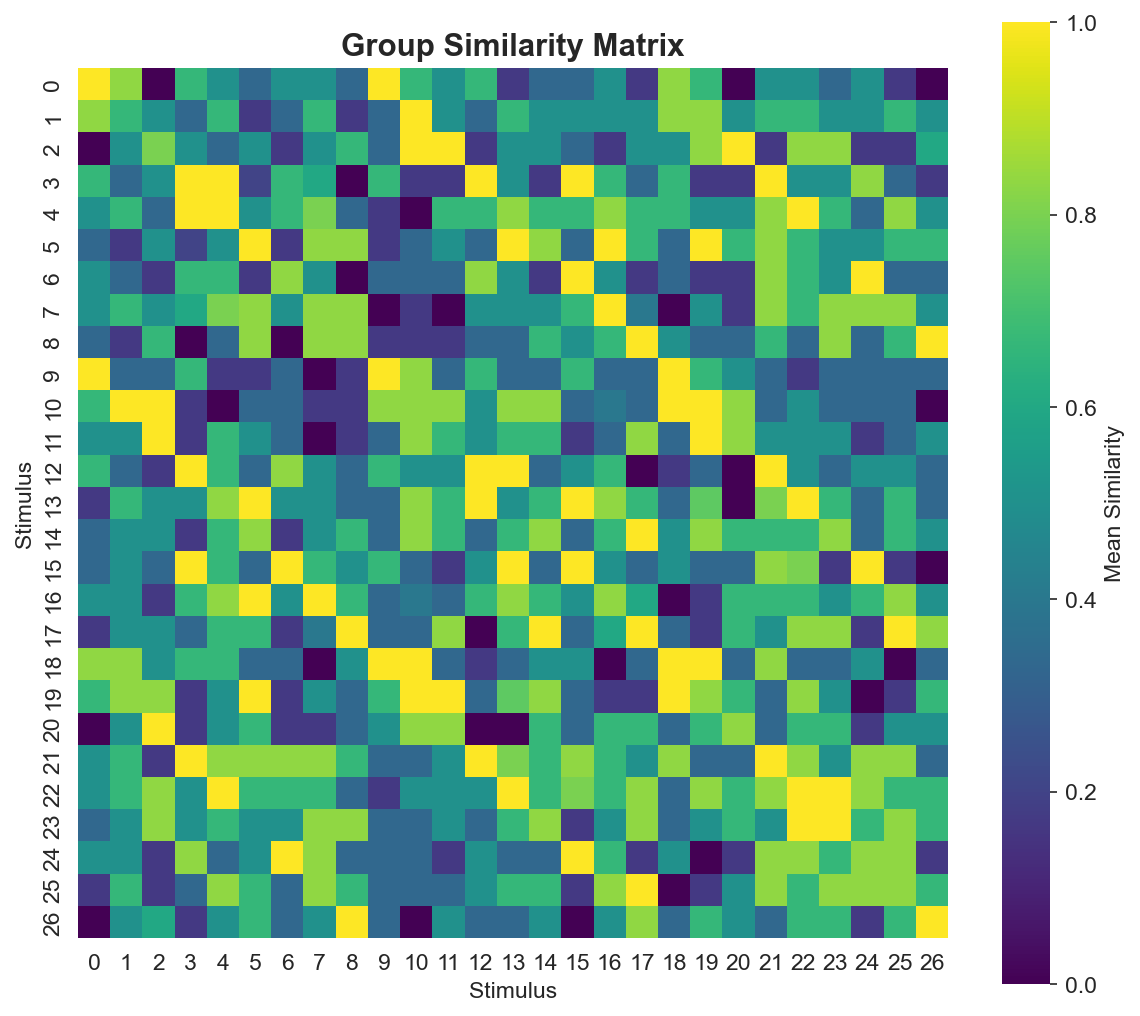

In [7]:
fig, ax = plt.subplots(figsize=(8,7))

sns.heatmap(
    group_similarity_df,
    cmap="viridis",
    square=True,
    vmin=0,
    vmax=1,
    cbar_kws={"label":"Mean Similarity"},
    ax=ax
)

ax.set_title("Group Similarity Matrix", fontsize=15, weight="bold")
ax.set_xlabel("Stimulus")
ax.set_ylabel("Stimulus")

plt.tight_layout()
plt.show()

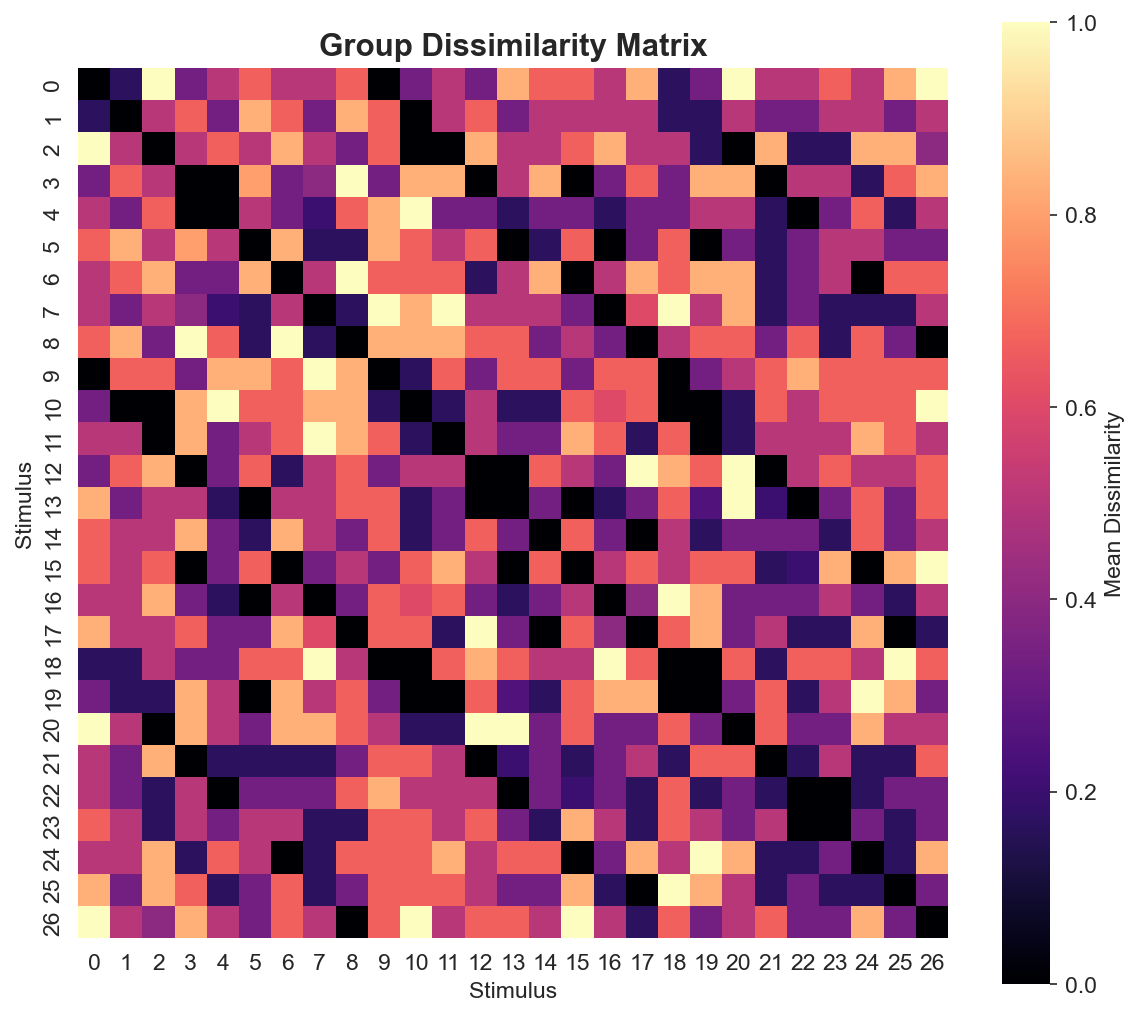

In [8]:
fig, ax = plt.subplots(figsize=(8,7))

sns.heatmap(
    group_dissimilarity_df,
    cmap="magma",
    square=True,
    vmin=0,
    vmax=1,
    cbar_kws={"label":"Mean Dissimilarity"},
    ax=ax
)

ax.set_title("Group Dissimilarity Matrix", fontsize=15, weight="bold")
ax.set_xlabel("Stimulus")
ax.set_ylabel("Stimulus")

plt.tight_layout()
plt.show()

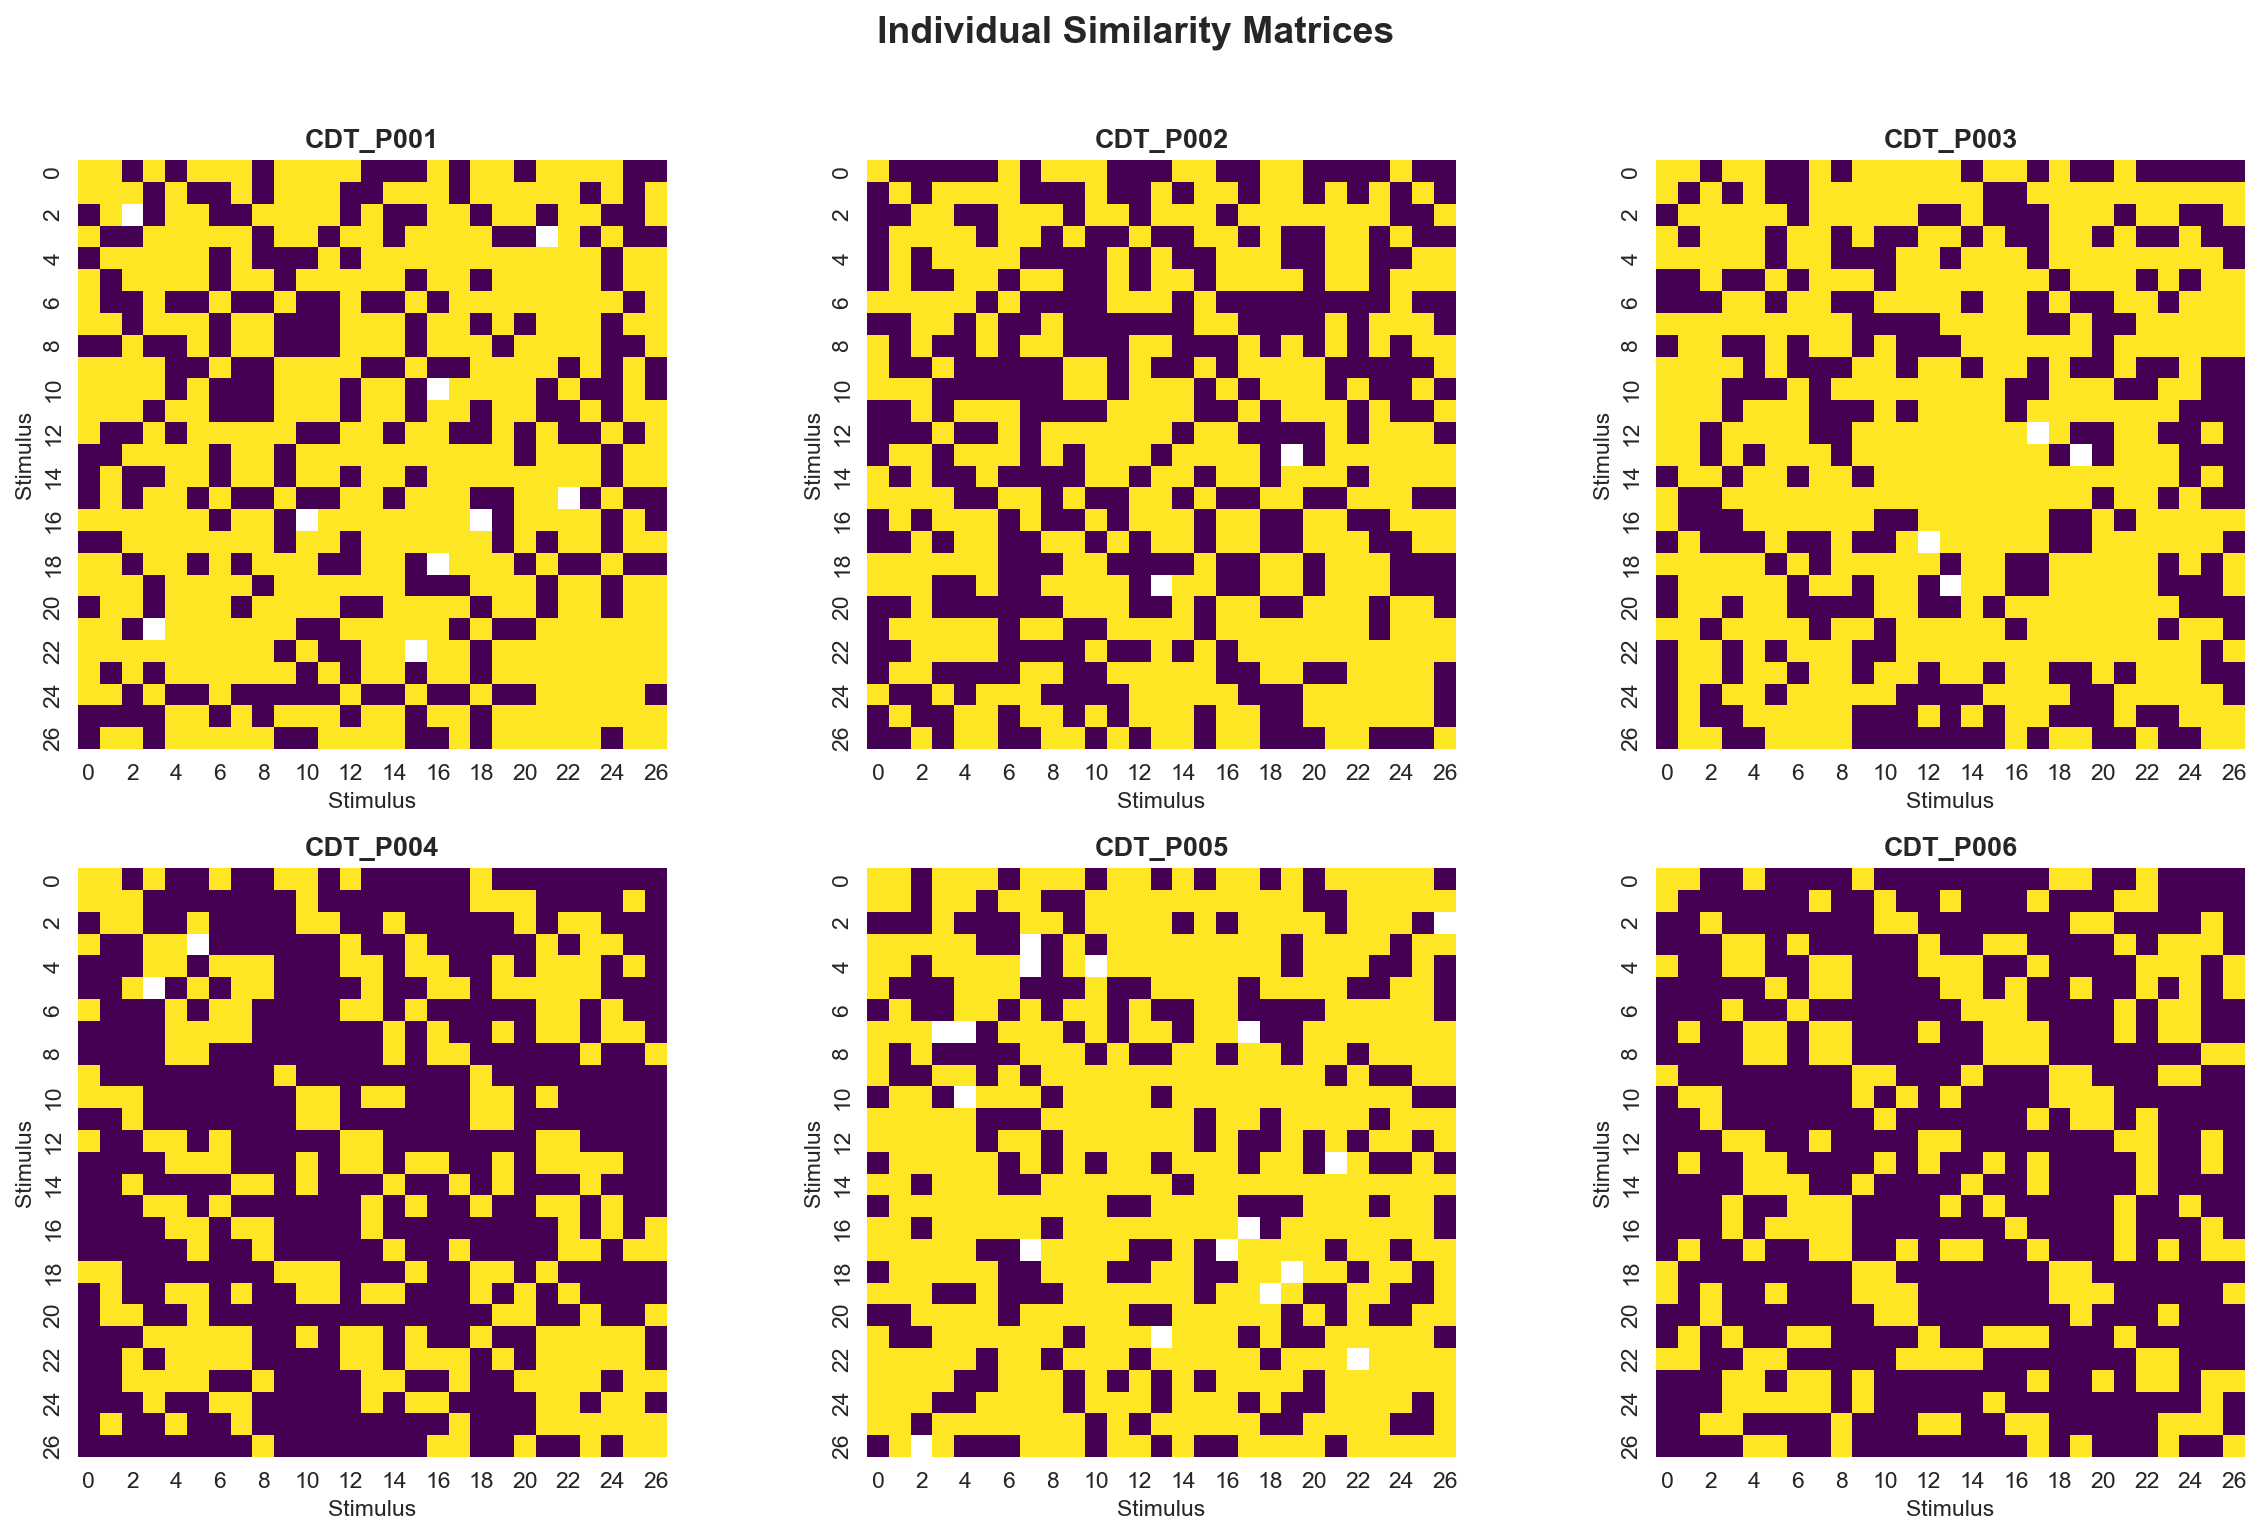

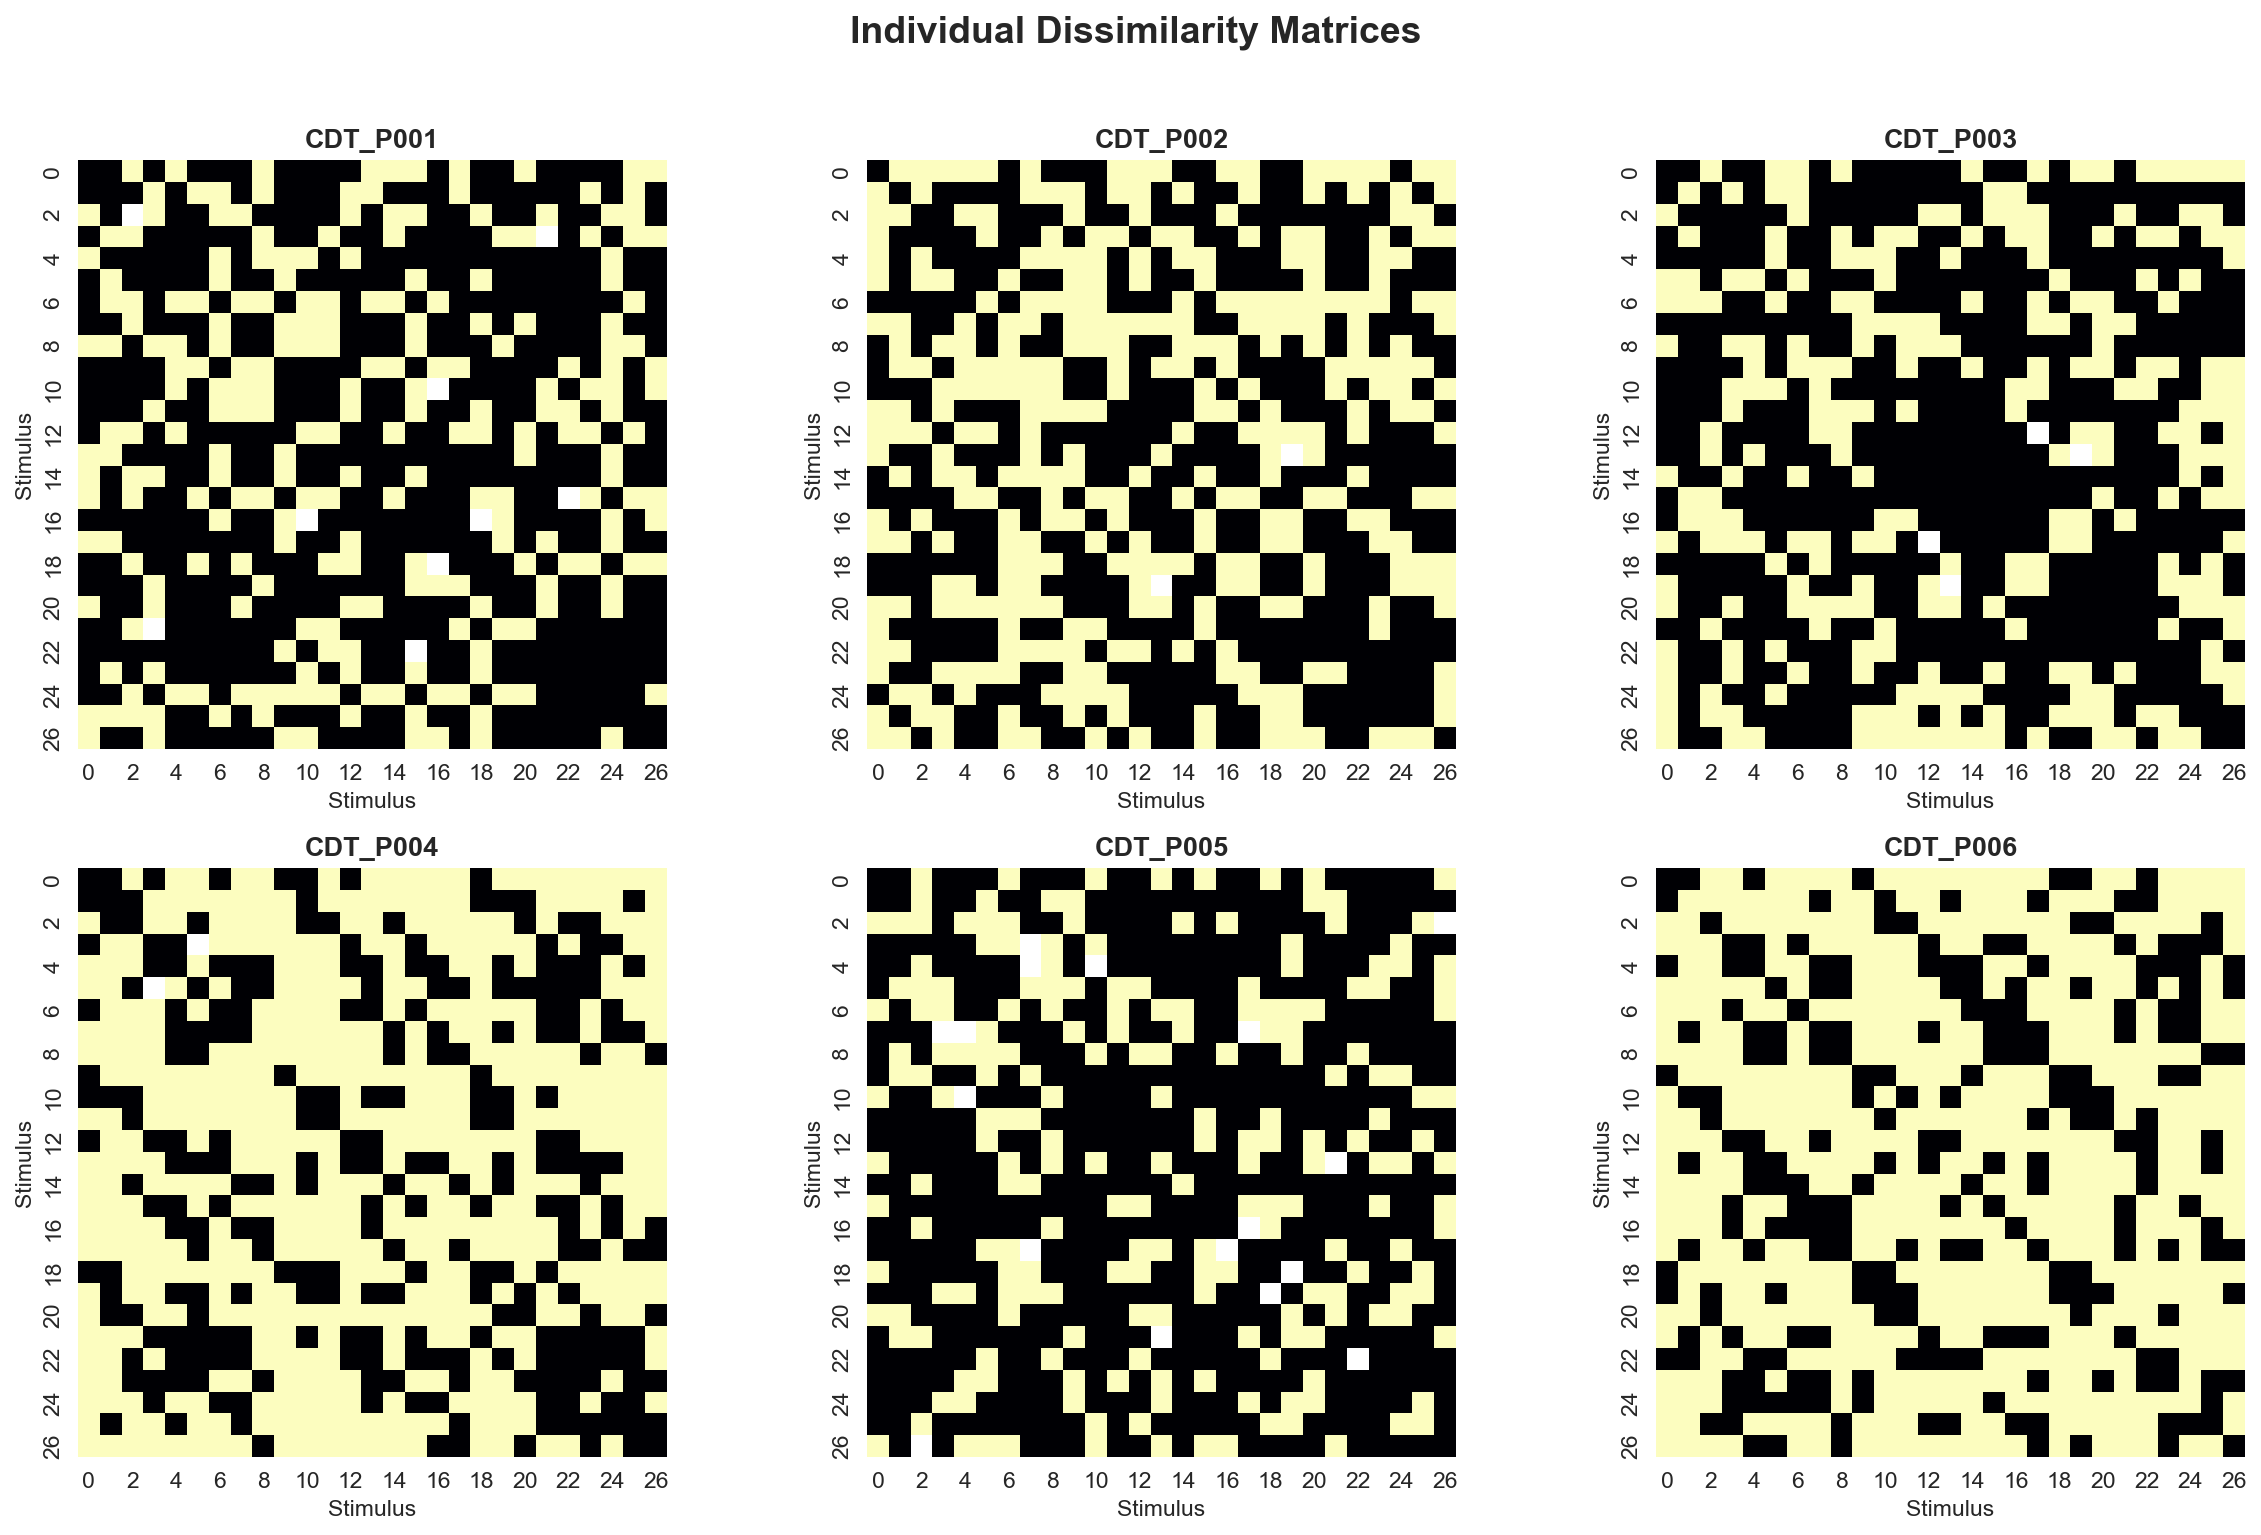

In [9]:
# ----------------------------------------------------
# Individual Similarity Matrices
# ----------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for ax, (pid, data) in zip(axes, participants.items()):

    sns.heatmap(
        data["matrix"],
        cmap="viridis",
        square=True,
        vmin=0,
        vmax=1,
    
        cbar=False,
        ax=ax
    )

    ax.set_title(pid, fontsize=13, weight="bold")
    ax.set_xlabel("Stimulus")
    ax.set_ylabel("Stimulus")

plt.suptitle(
    "Individual Similarity Matrices",
    fontsize=18,
    weight="bold",
    y=1.02
)

plt.tight_layout()

plt.show()
# ----------------------------------------------------
# Individual Dissimilarity Matrices
# ----------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for ax, (pid, data) in zip(axes, participants.items()):

    diss = 1 - data["matrix"]

    sns.heatmap(
        diss,
        cmap="magma",
        square=True,
        vmin=0,
        vmax=1,
        cbar=False,
        ax=ax
    )

    ax.set_title(pid, fontsize=13, weight="bold")
    ax.set_xlabel("Stimulus")
    ax.set_ylabel("Stimulus")

plt.suptitle(
    "Individual Dissimilarity Matrices",
    fontsize=18,
    weight="bold",
    y=1.02
)

plt.tight_layout()

plt.show()

In [10]:
# ----------------------------------------------------------
# Matrices used for MDS analysis
# (Participant matrices have NaNs replaced with group mean)
# ----------------------------------------------------------

analysis_matrices = {}

# Group matrix
analysis_matrices["Group"] = group_similarity.copy()

# Participant matrices
for pid, data in participants.items():

    matrix = data["matrix"].to_numpy().copy()

    # Replace NaNs using group similarity
    nan_mask = np.isnan(matrix)

    matrix[nan_mask] = group_similarity[nan_mask]

    analysis_matrices[pid] = matrix

print("Matrices ready for MDS:")
print(analysis_matrices.keys())

Matrices ready for MDS:
dict_keys(['Group', 'CDT_P001', 'CDT_P002', 'CDT_P003', 'CDT_P004', 'CDT_P005', 'CDT_P006'])


In [11]:
from sklearn.manifold import MDS

mds_results = {}

for name, matrix in analysis_matrices.items():

    diss = 1 - matrix

    np.fill_diagonal(diss, 0)

    mds = MDS(
        n_components=2,
        metric=True,
        dissimilarity="precomputed",
        random_state=42,
        n_init=20,
        max_iter=1000
    )

    coords = mds.fit_transform(diss)

    mds_results[name] = {
        "coords": coords,
        "stress": mds.stress_
    }

print("Finished computing MDS.")

/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:760: FutureWarning: Use metric_mds=True instead of metric=True. The support for metric={True/False} will be dropped in 1.10.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotac

Finished computing MDS.


/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:760: FutureWarning: Use metric_mds=True instead of metric=True. The support for metric={True/False} will be dropped in 1.10.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotac

In [12]:
stress_table = pd.DataFrame({
    "Dataset": list(mds_results.keys()),
    "Stress": [mds_results[k]["stress"] for k in mds_results]
})

stress_table

,Dataset,Stress
0,Group,9.368855
1,CDT_P001,53.026083
2,CDT_P002,60.775101
3,CDT_P003,57.113083
4,CDT_P004,41.165518
5,CDT_P005,54.793298
6,CDT_P006,47.828454


In [13]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def plot_mds(ax, coords, mode):

    if mode == "plain":

        ax.scatter(
            coords[:,0],
            coords[:,1],
            s=40,
            color="steelblue"
        )

    elif mode == "waveform":

        for wf in metadata["Waveform"].unique():

            idx = metadata["Waveform"] == wf

            ax.scatter(
                coords[idx,0],
                coords[idx,1],
                s=45,
                c=waveform_colors[wf],
                marker=markers[wf]
            )

        legend_elements = [

            Line2D([0],[0],
                   marker='o',
                   color='w',
                   markerfacecolor=waveform_colors["Sine"],
                   markersize=8,
                   label='Sine'),

            Line2D([0],[0],
                   marker='s',
                   color='w',
                   markerfacecolor=waveform_colors["Square"],
                   markersize=8,
                   label='Square'),

            Line2D([0],[0],
                   marker='^',
                   color='w',
                   markerfacecolor=waveform_colors["Saw"],
                   markersize=8,
                   label='Saw')
        ]

        ax.legend(
            handles=legend_elements,
            fontsize=6,
            loc="upper left",
            frameon=True
        )

    elif mode == "ifi":

        sc = ax.scatter(
            coords[:,0],
            coords[:,1],
            s=45,
            c=metadata["IFI"],
            cmap="plasma"
        )

        plt.colorbar(
            sc,
            ax=ax,
            fraction=0.045,
            pad=0.03
        )

    elif mode == "am":

        sc = ax.scatter(
            coords[:,0],
            coords[:,1],
            s=45,
            c=metadata["AM"],
            cmap="cool"
        )

        plt.colorbar(
            sc,
            ax=ax,
            fraction=0.045,
            pad=0.03
        )

    # ---- Labels ---- #

    for i in range(27):

        ax.annotate(
            str(i+1),
            (coords[i,0],coords[i,1]),
            fontsize=6,
            xytext=(2,2),
            textcoords="offset points"
        )

    ax.set_xticks([])
    ax.set_yticks([])

NameError: name 'waveform_colors' is not defined

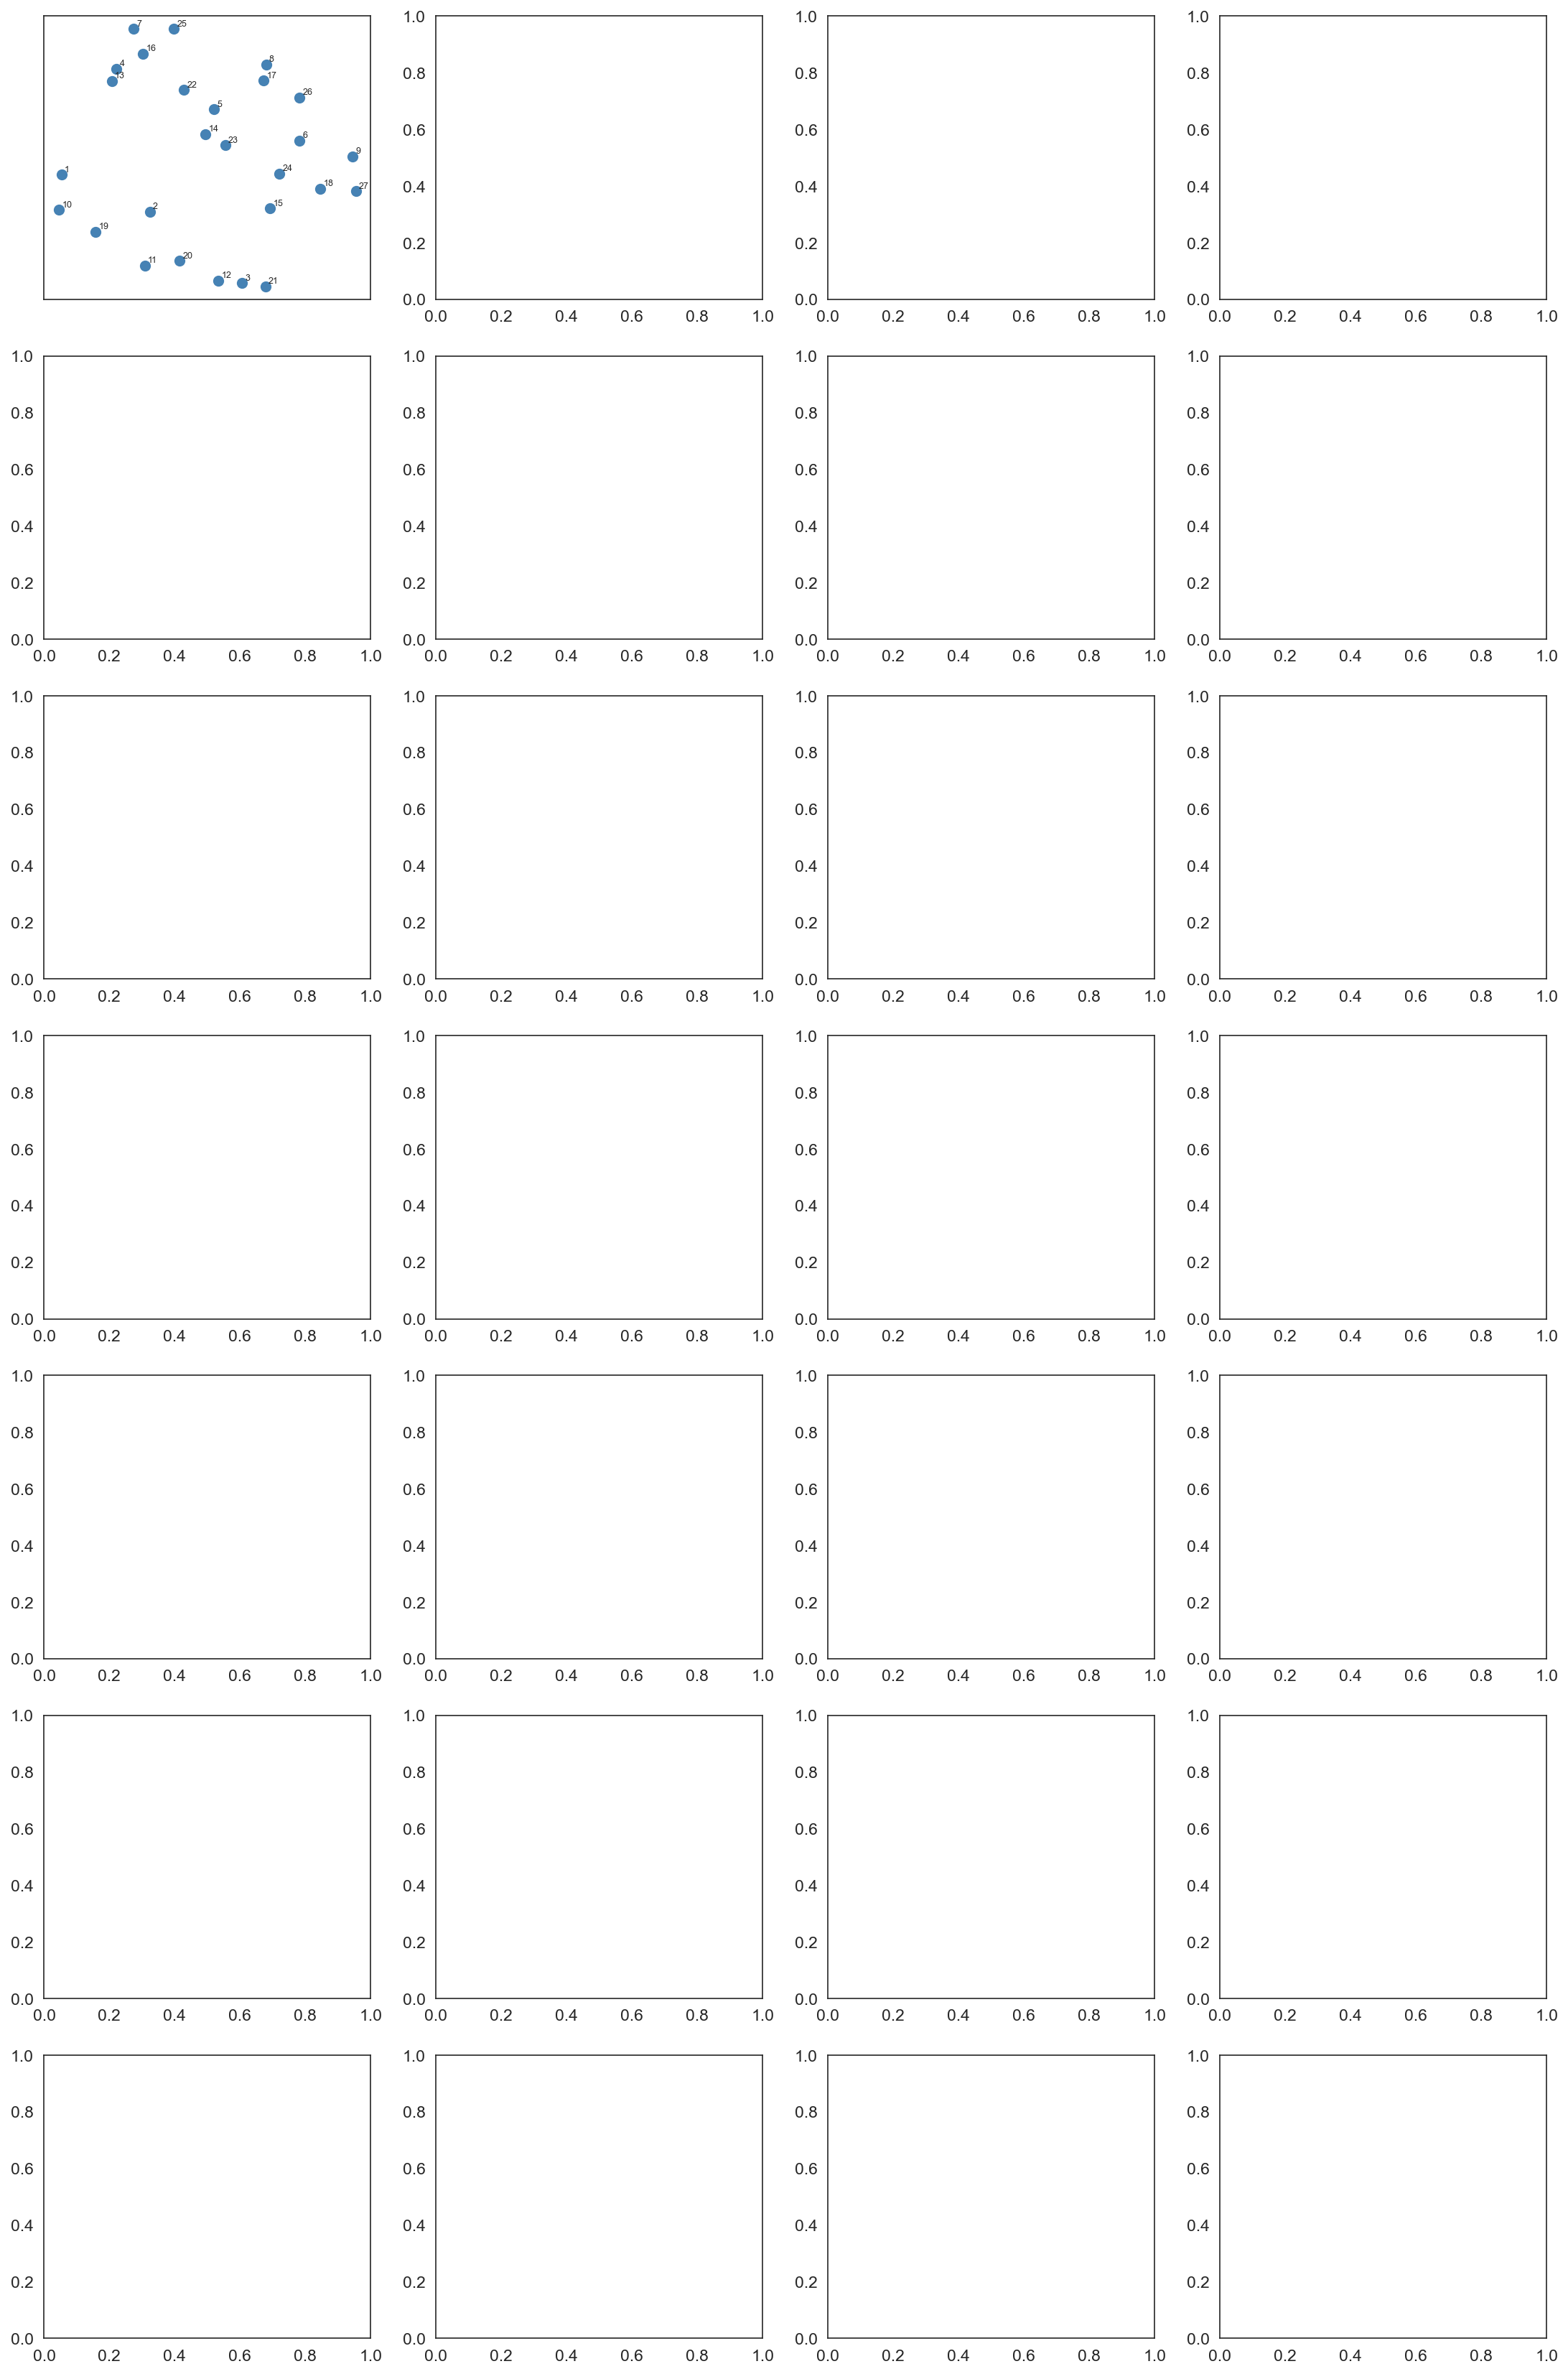

In [14]:
datasets = list(mds_results.keys())

titles = [
    "MDS",
    "Waveform",
    "IFI",
    "AM Depth"
]

fig, axes = plt.subplots(

    nrows=len(datasets),
    ncols=4,

    figsize=(18,4*len(datasets))

)

# Fix axes shape if only one participant
if len(datasets)==1:
    axes=np.expand_dims(axes,0)

for r,name in enumerate(datasets):

    coords=mds_results[name]["coords"]

    plot_mds(axes[r,0],coords,"plain")
    plot_mds(axes[r,1],coords,"waveform")
    plot_mds(axes[r,2],coords,"ifi")
    plot_mds(axes[r,3],coords,"am")

    # Row title
    axes[r,1].set_title(
        name,
        fontsize=13,
        weight="bold",
        pad=18
    )

    # Column titles only once
    if r==0:

        axes[r,0].set_title("MDS",fontsize=12,weight="bold",pad=18)

        axes[r,1].set_title("Waveform",fontsize=12,weight="bold",pad=18)

        axes[r,2].set_title("IFI",fontsize=12,weight="bold",pad=18)

        axes[r,3].set_title("AM Depth",fontsize=12,weight="bold",pad=18)

plt.tight_layout()

plt.show()

In [15]:
import pandas as pd

stress_df = pd.DataFrame({
    "Dataset": list(mds_results.keys()),
    "Raw Stress": [mds_results[k]["stress"] for k in mds_results]
})

stress_df

,Dataset,Raw Stress
0,Group,9.368855
1,CDT_P001,53.026083
2,CDT_P002,60.775101
3,CDT_P003,57.113083
4,CDT_P004,41.165518
5,CDT_P005,54.793298
6,CDT_P006,47.828454


In [16]:
from scipy.spatial.distance import pdist, squareform
import numpy as np

stress1 = []

for name in mds_results:

    coords = mds_results[name]["coords"]

    fitted = squareform(pdist(coords))

    original = 1 - analysis_matrices[name]

    np.fill_diagonal(original, 0)

    numerator = np.sum((original - fitted) ** 2)
    denominator = np.sum(original ** 2)

    s1 = np.sqrt(numerator / denominator)

    stress1.append(s1)

stress_df["Stress-1"] = stress1

stress_df

,Dataset,Raw Stress,Stress-1
0,Group,9.368855,0.298756
1,CDT_P001,53.026083,0.658194
2,CDT_P002,60.775101,0.606790
3,CDT_P003,57.113083,0.670439
4,CDT_P004,41.165518,0.419752
5,CDT_P005,54.793298,0.726130
6,CDT_P006,47.828454,0.440936


In [17]:
stress_df["Raw Stress"] = stress_df["Raw Stress"].round(2)
stress_df["Stress-1"] = stress_df["Stress-1"].round(3)

stress_df

,Dataset,Raw Stress,Stress-1
0,Group,9.37,0.299
1,CDT_P001,53.03,0.658
2,CDT_P002,60.78,0.607
3,CDT_P003,57.11,0.670
4,CDT_P004,41.17,0.420
5,CDT_P005,54.79,0.726
6,CDT_P006,47.83,0.441


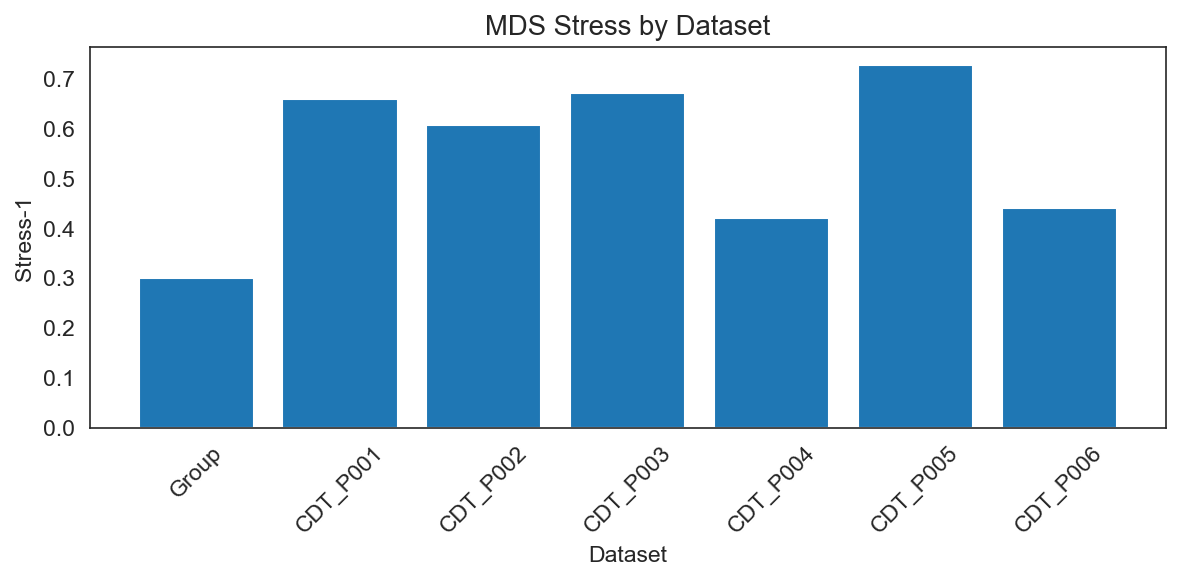

In [18]:
plt.figure(figsize=(8,4))

plt.bar(
    stress_df["Dataset"],
    stress_df["Stress-1"]
)

plt.ylabel("Stress-1")
plt.xlabel("Dataset")
plt.title("MDS Stress by Dataset")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:760: FutureWarning: Use metric_mds=True instead of metric=True. The support for metric={True/False} will be dropped in 1.10.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotac

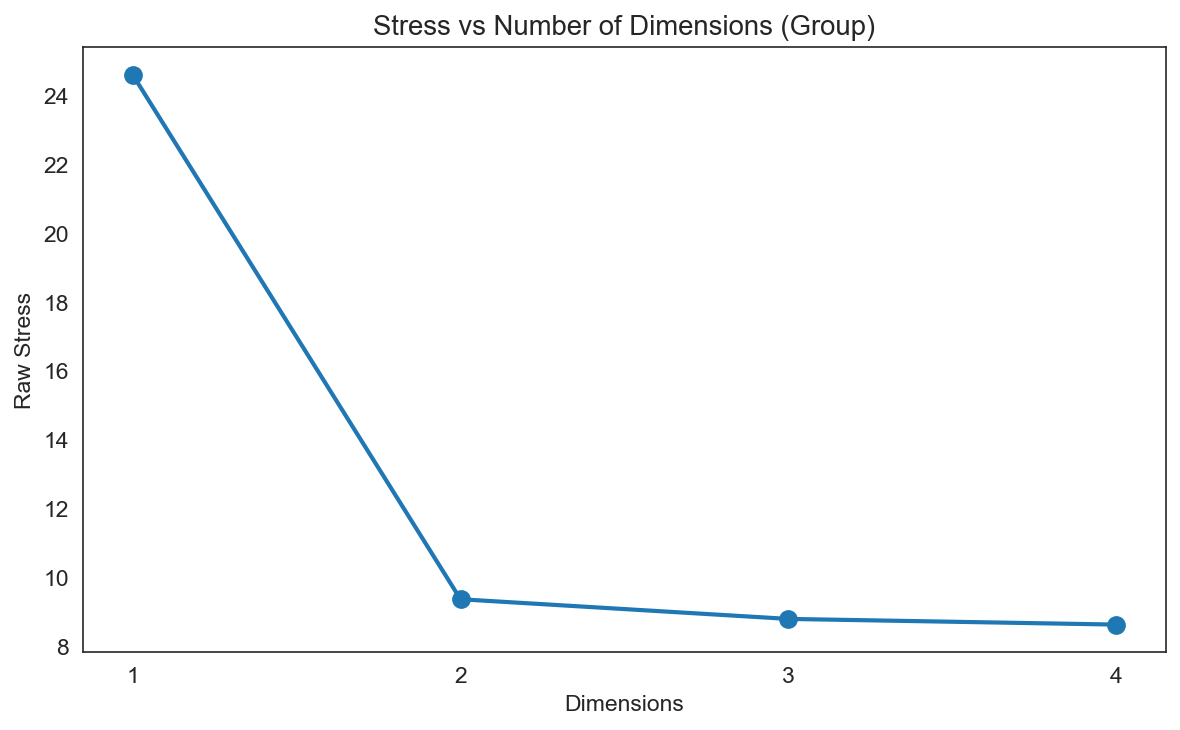

Stress values:
1D : 24.61
2D : 9.37
3D : 8.80
4D : 8.63


In [19]:
from sklearn.manifold import MDS
import matplotlib.pyplot as plt

dimensions = [1, 2, 3, 4]
stress_values = []

# Group dissimilarity matrix
group_dissimilarity = 1 - group_similarity
np.fill_diagonal(group_dissimilarity, 0)

for dim in dimensions:

    mds = MDS(
        n_components=dim,
        metric=True,
        dissimilarity='precomputed',
        random_state=42,
        n_init=20,
        max_iter=1000
    )

    mds.fit(group_dissimilarity)

    stress_values.append(mds.stress_)

plt.figure(figsize=(8,5))

plt.plot(
    dimensions,
    stress_values,
    marker='o',
    linewidth=2,
    markersize=8
)

plt.xticks(dimensions)

plt.xlabel("Dimensions")
plt.ylabel("Raw Stress")

plt.title("Stress vs Number of Dimensions (Group)")

plt.grid(False)

plt.tight_layout()
plt.show()

print("Stress values:")
for d, s in zip(dimensions, stress_values):
    print(f"{d}D : {s:.2f}")

In [20]:
from scipy.stats import pearsonr

group_coords = mds_results["Group"]["coords"]

ifi = metadata["IFI"]

r1, p1 = pearsonr(group_coords[:,0], ifi)

r2, p2 = pearsonr(group_coords[:,1], ifi)

print("Dimension 1 vs IFI")
print(f"r = {r1:.3f}, p = {p1:.4f}")

print()

print("Dimension 2 vs IFI")
print(f"r = {r2:.3f}, p = {p2:.4f}")

Dimension 1 vs IFI
r = 0.488, p = 0.0099

Dimension 2 vs IFI
r = 0.752, p = 0.0000


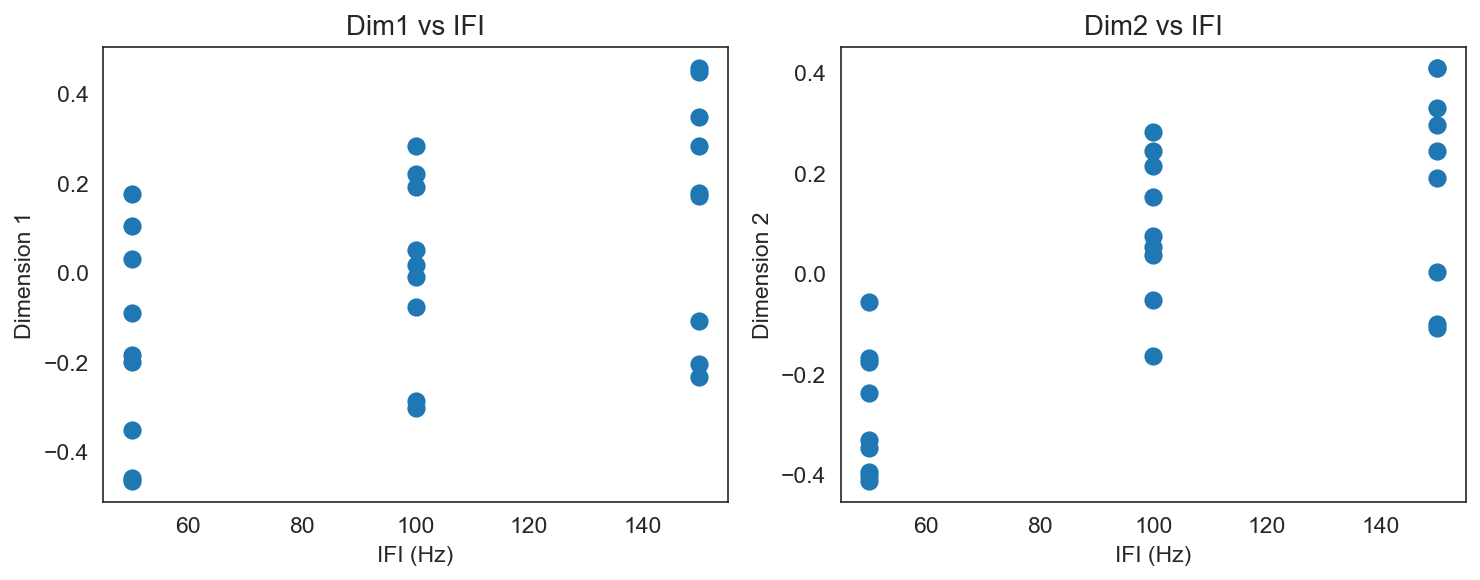

In [21]:
fig, axes = plt.subplots(1,2, figsize=(10,4))

axes[0].scatter(
    ifi,
    group_coords[:,0],
    s=60
)

axes[0].set_xlabel("IFI (Hz)")
axes[0].set_ylabel("Dimension 1")
axes[0].set_title("Dim1 vs IFI")

axes[1].scatter(
    ifi,
    group_coords[:,1],
    s=60
)

axes[1].set_xlabel("IFI (Hz)")
axes[1].set_ylabel("Dimension 2")
axes[1].set_title("Dim2 vs IFI")

plt.tight_layout()
plt.show()

In [22]:
am = metadata["AM"]

r1,p1 = pearsonr(group_coords[:,0], am)

r2,p2 = pearsonr(group_coords[:,1], am)

print("Dimension 1 vs AM")
print(f"r = {r1:.3f}, p = {p1:.4f}")

print()

print("Dimension 2 vs AM")
print(f"r = {r2:.3f}, p = {p2:.4f}")

Dimension 1 vs AM
r = 0.833, p = 0.0000

Dimension 2 vs AM
r = -0.538, p = 0.0038


In [23]:
corr_results = pd.DataFrame({
    "Parameter": ["IFI", "IFI", "AM Depth", "AM Depth"],
    "MDS Dimension": ["Dim 1", "Dim 2", "Dim 1", "Dim 2"],
    "r": [0.488, 0.752, 0.833, -0.538],
    "p-value": [0.0099, 0.0000, 0.0000, 0.0038]
})

corr_results["r"] = corr_results["r"].round(3)
corr_results["p-value"] = corr_results["p-value"].round(4)

corr_results

,Parameter,MDS Dimension,r,p-value
0,IFI,Dim 1,0.488,0.0099
1,IFI,Dim 2,0.752,0.0000
2,AM Depth,Dim 1,0.833,0.0000
3,AM Depth,Dim 2,-0.538,0.0038


In [24]:
from scipy.stats import f_oneway

group_coords = mds_results["Group"]["coords"]

temp = metadata.copy()

temp["Dim1"] = group_coords[:,0]
temp["Dim2"] = group_coords[:,1]

# -----------------------------
# Dimension 1
# -----------------------------

groups_dim1 = [
    temp[temp["Waveform"] == wf]["Dim1"]
    for wf in temp["Waveform"].unique()
]

F1, p1 = f_oneway(*groups_dim1)

# -----------------------------
# Dimension 2
# -----------------------------

groups_dim2 = [
    temp[temp["Waveform"] == wf]["Dim2"]
    for wf in temp["Waveform"].unique()
]

F2, p2 = f_oneway(*groups_dim2)

print(f"Dimension 1: F = {F1:.3f}, p = {p1:.4f}")
print(f"Dimension 2: F = {F2:.3f}, p = {p2:.4f}")

Dimension 1: F = 0.403, p = 0.6728
Dimension 2: F = 0.381, p = 0.6875


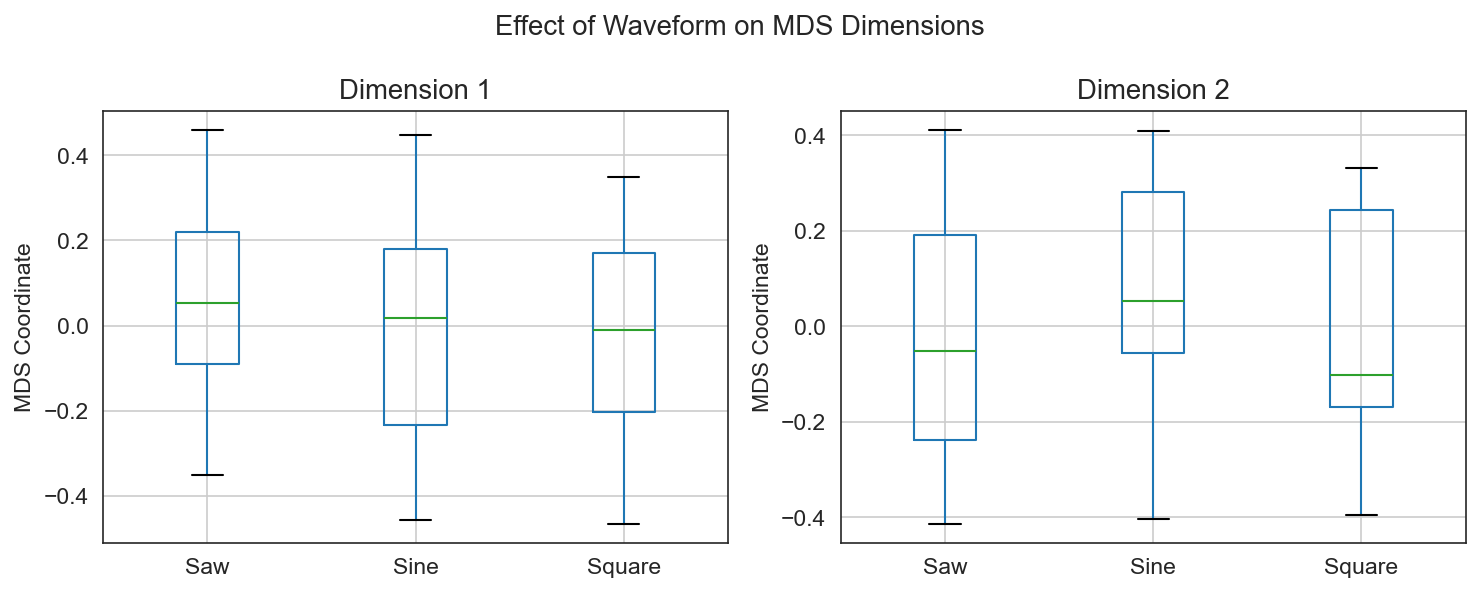

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

temp.boxplot(
    column="Dim1",
    by="Waveform",
    ax=axes[0]
)

axes[0].set_title("Dimension 1")
axes[0].set_xlabel("")
axes[0].set_ylabel("MDS Coordinate")

temp.boxplot(
    column="Dim2",
    by="Waveform",
    ax=axes[1]
)

axes[1].set_title("Dimension 2")
axes[1].set_xlabel("")
axes[1].set_ylabel("MDS Coordinate")

plt.suptitle("Effect of Waveform on MDS Dimensions")

plt.tight_layout()

plt.show()

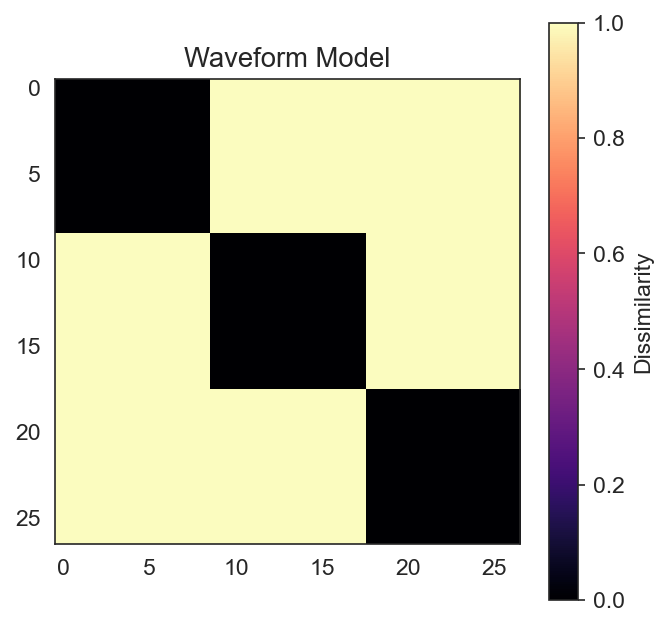

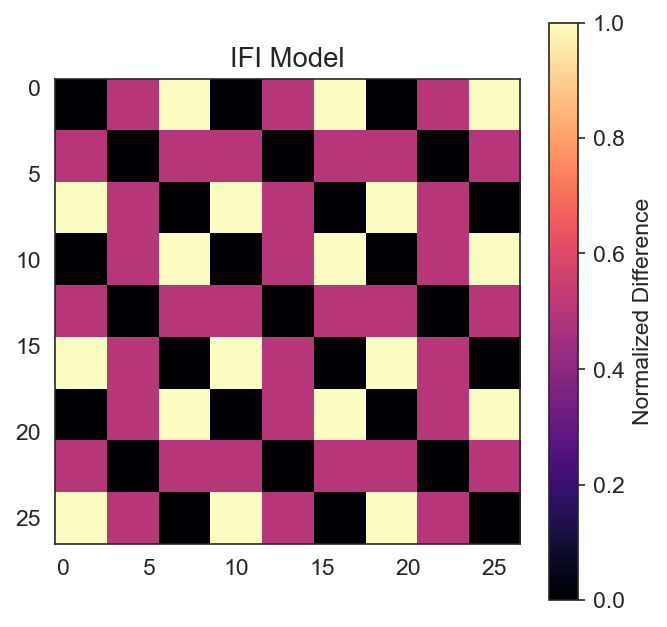

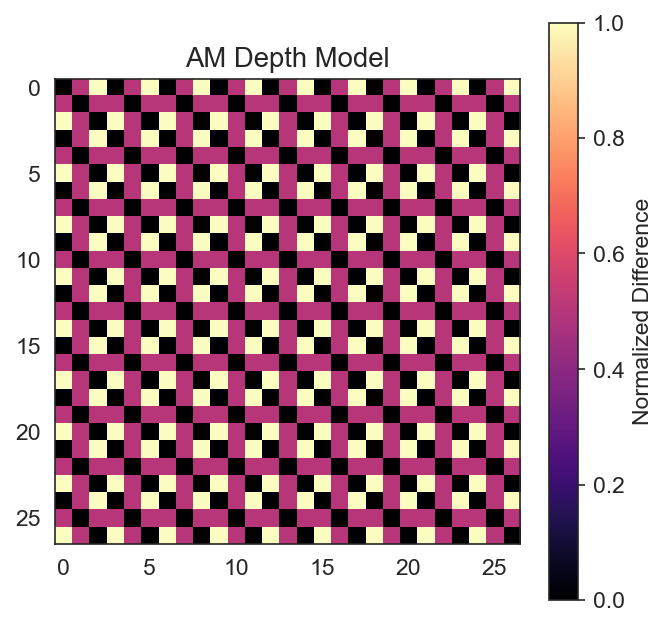

In [26]:
waveforms = metadata["Waveform"].values

waveform_model = np.zeros((27,27))

for i in range(27):
    for j in range(27):

        if waveforms[i] == waveforms[j]:
            waveform_model[i,j] = 0
        else:
            waveform_model[i,j] = 1

plt.figure(figsize=(5,5))
plt.imshow(waveform_model, cmap="magma")
plt.title("Waveform Model")
plt.colorbar(label="Dissimilarity")
plt.show()
ifi = metadata["IFI"].values

ifi_model = np.zeros((27,27))

for i in range(27):
    for j in range(27):

        ifi_model[i,j] = abs(ifi[i]-ifi[j])

# Normalize to 0-1
ifi_model = ifi_model / ifi_model.max()

plt.figure(figsize=(5,5))
plt.imshow(ifi_model, cmap="magma")
plt.title("IFI Model")
plt.colorbar(label="Normalized Difference")
plt.show()
am = metadata["AM"].values

am_model = np.zeros((27,27))

for i in range(27):
    for j in range(27):

        am_model[i,j] = abs(am[i]-am[j])

am_model = am_model / am_model.max()

plt.figure(figsize=(5,5))
plt.imshow(am_model, cmap="magma")
plt.title("AM Depth Model")
plt.colorbar(label="Normalized Difference")
plt.show()

In [27]:
from scipy.stats import spearmanr

upper = np.triu_indices(27, k=1)

perceptual = group_dissimilarity[upper]

waveform_upper = waveform_model[upper]
ifi_upper = ifi_model[upper]
am_upper = am_model[upper]

In [28]:
rsa_results = []

for name, model in zip(
    ["Waveform", "IFI", "AM Depth"],
    [waveform_upper, ifi_upper, am_upper]
):

    r, p = spearmanr(perceptual, model)

    rsa_results.append([name, r, p])

rsa_results = pd.DataFrame(
    rsa_results,
    columns=["Model","Spearman r","p-value"]
)

rsa_results["Spearman r"] = rsa_results["Spearman r"].round(3)
rsa_results["p-value"] = rsa_results["p-value"].round(4)

rsa_results

,Model,Spearman r,p-value
0,Waveform,0.021,0.695
1,IFI,0.425,0.000
2,AM Depth,0.507,0.000


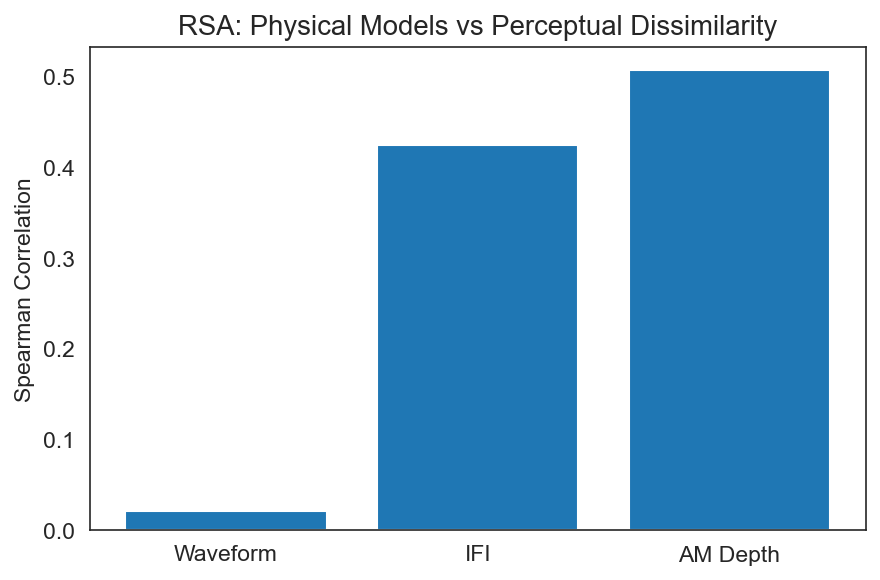

In [29]:
plt.figure(figsize=(6,4))

plt.bar(
    rsa_results["Model"],
    rsa_results["Spearman r"]
)

plt.ylabel("Spearman Correlation")
plt.title("RSA: Physical Models vs Perceptual Dissimilarity")

plt.tight_layout()
plt.show()

In [30]:
import statsmodels.formula.api as smf

group_coords = mds_results["Group"]["coords"]

reg_df = metadata.copy()

reg_df["Dim1"] = group_coords[:,0]
reg_df["Dim2"] = group_coords[:,1]

reg_df.head()

,Stimulus,Waveform,IFI,AM,Dim1,Dim2
0,1,Sine,50,30,-0.457876,-0.055995
1,2,Sine,50,60,-0.182481,-0.174647
2,3,Sine,50,90,0.103938,-0.402839
3,4,Sine,100,30,-0.286478,0.282456
4,5,Sine,100,60,0.017399,0.153396


In [31]:
model_dim1 = smf.ols(
    "Dim1 ~ IFI + AM + C(Waveform)",
    data=reg_df
).fit()

print(model_dim1.summary())

                            OLS Regression Results                            
Dep. Variable:                   Dim1   R-squared:                       0.965
Model:                            OLS   Adj. R-squared:                  0.958
Method:                 Least Squares   F-statistic:                     149.4
Date:                Tue, 07 Jul 2026   Prob (F-statistic):           1.31e-15
Time:                        13:59:46   Log-Likelihood:                 43.288
No. Observations:                  27   AIC:                            -76.58
Df Residuals:                      22   BIC:                            -70.10
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                -0.77

In [32]:
model_dim2 = smf.ols(
    "Dim2 ~ IFI + AM + C(Waveform)",
    data=reg_df
).fit()

print(model_dim2.summary())

                            OLS Regression Results                            
Dep. Variable:                   Dim2   R-squared:                       0.885
Model:                            OLS   Adj. R-squared:                  0.864
Method:                 Least Squares   F-statistic:                     42.30
Date:                Tue, 07 Jul 2026   Prob (F-statistic):           5.02e-10
Time:                        13:59:54   Log-Likelihood:                 27.919
No. Observations:                  27   AIC:                            -45.84
Df Residuals:                      22   BIC:                            -39.36
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                -0.16

In [33]:
results = pd.DataFrame({

    "Predictor": model_dim1.params.index,

    "Dim1 Beta": model_dim1.params.values,

    "Dim1 p": model_dim1.pvalues.values,

    "Dim2 Beta": model_dim2.params.values,

    "Dim2 p": model_dim2.pvalues.values

})

results.round(4)

,Predictor,Dim1 Beta,Dim1 p,Dim2 Beta,Dim2 p
0,Intercept,-0.7734,0.0000,-0.1647,0.0302
1,C(Waveform)[T.Sine],-0.0771,0.0061,0.0949,0.0463
2,C(Waveform)[T.Square],-0.1114,0.0002,0.0011,0.9804
3,IFI,0.0031,0.0000,0.0047,0.0000
4,AM,0.0088,0.0000,-0.0056,0.0000


In [34]:
import statsmodels.formula.api as smf

group_coords = mds_results["Group"]["coords"]

reg_df = metadata.copy()

reg_df["Dim1"] = group_coords[:, 0]
reg_df["Dim2"] = group_coords[:, 1]

reg_df.head()

,Stimulus,Waveform,IFI,AM,Dim1,Dim2
0,1,Sine,50,30,-0.457876,-0.055995
1,2,Sine,50,60,-0.182481,-0.174647
2,3,Sine,50,90,0.103938,-0.402839
3,4,Sine,100,30,-0.286478,0.282456
4,5,Sine,100,60,0.017399,0.153396


In [35]:
model_dim1 = smf.ols(
    "Dim1 ~ IFI + AM + C(Waveform)",
    data=reg_df
).fit()

print(model_dim1.summary())

                            OLS Regression Results                            
Dep. Variable:                   Dim1   R-squared:                       0.965
Model:                            OLS   Adj. R-squared:                  0.958
Method:                 Least Squares   F-statistic:                     149.4
Date:                Tue, 07 Jul 2026   Prob (F-statistic):           1.31e-15
Time:                        14:00:00   Log-Likelihood:                 43.288
No. Observations:                  27   AIC:                            -76.58
Df Residuals:                      22   BIC:                            -70.10
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                -0.77

In [36]:
model_dim2 = smf.ols(
    "Dim2 ~ IFI + AM + C(Waveform)",
    data=reg_df
).fit()

print(model_dim2.summary())

                            OLS Regression Results                            
Dep. Variable:                   Dim2   R-squared:                       0.885
Model:                            OLS   Adj. R-squared:                  0.864
Method:                 Least Squares   F-statistic:                     42.30
Date:                Tue, 07 Jul 2026   Prob (F-statistic):           5.02e-10
Time:                        14:00:03   Log-Likelihood:                 27.919
No. Observations:                  27   AIC:                            -45.84
Df Residuals:                      22   BIC:                            -39.36
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                -0.16

In [37]:
summary_table = pd.DataFrame({

    "Predictor": model_dim1.params.index,

    "Dim1 β": model_dim1.params.values,
    "Dim1 p": model_dim1.pvalues.values,

    "Dim2 β": model_dim2.params.values,
    "Dim2 p": model_dim2.pvalues.values

})

summary_table = summary_table.round(4)

summary_table

,Predictor,Dim1 β,Dim1 p,Dim2 β,Dim2 p
0,Intercept,-0.7734,0.0000,-0.1647,0.0302
1,C(Waveform)[T.Sine],-0.0771,0.0061,0.0949,0.0463
2,C(Waveform)[T.Square],-0.1114,0.0002,0.0011,0.9804
3,IFI,0.0031,0.0000,0.0047,0.0000
4,AM,0.0088,0.0000,-0.0056,0.0000


In [38]:
model_fit = pd.DataFrame({

    "Model": ["Dimension 1", "Dimension 2"],

    "R²": [
        model_dim1.rsquared,
        model_dim2.rsquared
    ],

    "Adjusted R²": [
        model_dim1.rsquared_adj,
        model_dim2.rsquared_adj
    ],

    "F-statistic": [
        model_dim1.fvalue,
        model_dim2.fvalue
    ],

    "Model p-value": [
        model_dim1.f_pvalue,
        model_dim2.f_pvalue
    ]
})

model_fit.round(4)

,Model,R²,Adjusted R²,F-statistic,Model p-value
0,Dimension 1,0.9645,0.958,149.4387,0.0
1,Dimension 2,0.8849,0.864,42.3046,0.0


In [39]:
from sklearn.preprocessing import StandardScaler

std_df = reg_df.copy()

scaler = StandardScaler()

std_df[["IFI", "AM"]] = scaler.fit_transform(
    std_df[["IFI", "AM"]]
)

In [40]:
std_model = smf.ols(
    "Dim1 ~ IFI + AM + C(Waveform)",
    data=std_df
).fit()

print(std_model.summary())

                            OLS Regression Results                            
Dep. Variable:                   Dim1   R-squared:                       0.965
Model:                            OLS   Adj. R-squared:                  0.958
Method:                 Least Squares   F-statistic:                     149.4
Date:                Tue, 07 Jul 2026   Prob (F-statistic):           1.31e-15
Time:                        14:00:34   Log-Likelihood:                 43.288
No. Observations:                  27   AIC:                            -76.58
Df Residuals:                      22   BIC:                            -70.10
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.06

In [41]:
std_model2 = smf.ols(
    "Dim2 ~ IFI + AM + C(Waveform)",
    data=std_df
).fit()

print(std_model2.summary())

                            OLS Regression Results                            
Dep. Variable:                   Dim2   R-squared:                       0.885
Model:                            OLS   Adj. R-squared:                  0.864
Method:                 Least Squares   F-statistic:                     42.30
Date:                Tue, 07 Jul 2026   Prob (F-statistic):           5.02e-10
Time:                        14:00:37   Log-Likelihood:                 27.919
No. Observations:                  27   AIC:                            -45.84
Df Residuals:                      22   BIC:                            -39.36
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                -0.03

<Figure size 1050x600 with 0 Axes>

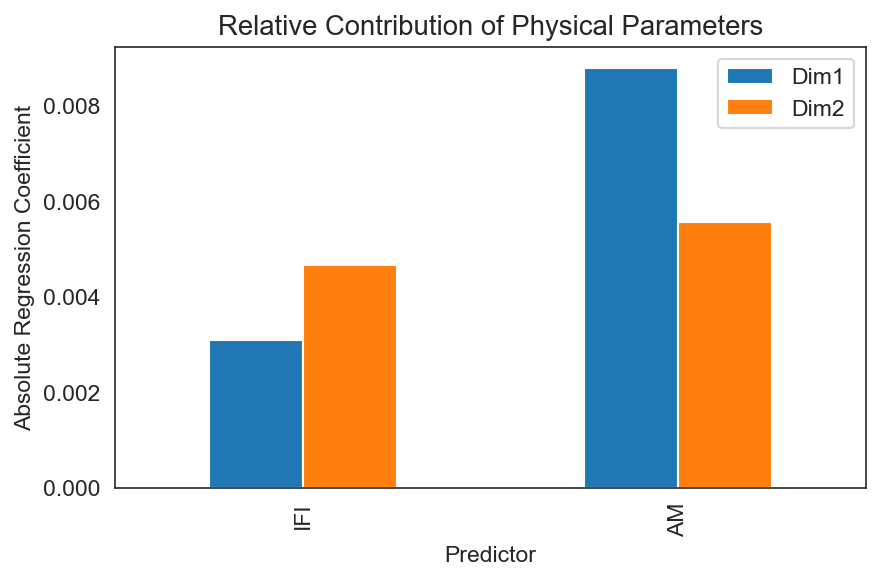

In [42]:
plt.figure(figsize=(7,4))

importance = pd.DataFrame({

    "Predictor":["IFI","AM"],

    "Dim1":[abs(model_dim1.params["IFI"]),
            abs(model_dim1.params["AM"])],

    "Dim2":[abs(model_dim2.params["IFI"]),
            abs(model_dim2.params["AM"])]
})

importance.plot(
    kind="bar",
    x="Predictor",
    figsize=(6,4)
)

plt.ylabel("Absolute Regression Coefficient")
plt.title("Relative Contribution of Physical Parameters")

plt.tight_layout()

plt.show()

In [43]:
pd.read_csv("../results/CDT_P001/CDT_P001_VD.csv").head(10)

,Presentation_Order,Stimulus_File,Description
0,1,S05_sine_IFI100_AM60.wav,Rough
1,2,S10_square_IFI50_AM30.wav,Rough
2,3,S09_sine_IFI150_AM90.wav,Stairs
3,4,S04_sine_IFI100_AM30.wav,Smooth
4,5,S20_saw_IFI50_AM60.wav,Crackers bursting
5,6,S06_sine_IFI100_AM90.wav,Engine sound
6,7,S19_saw_IFI50_AM30.wav,Rough
7,8,S24_saw_IFI100_AM90.wav,Engine sound
8,9,S26_saw_IFI150_AM60.wav,Rough
9,10,S08_sine_IFI150_AM60.wav,Stairs


In [44]:
from collections import Counter
import pandas as pd

summary = []

for stim, group in verbal.groupby("Stimulus_File"):

    words = group["Description"].str.lower().str.strip()

    common = Counter(words).most_common(1)[0]

    summary.append({
        "Stimulus_File": stim,
        "Label": common[0],
        "Count": common[1]
    })

labels = pd.DataFrame(summary)

display(labels)

,Stimulus_File,Label,Count
0,S01_sine_IFI50_AM30.wav,continuous,1
1,S02_sine_IFI50_AM60.wav,break,1
2,S03_sine_IFI50_AM90.wav,break break break,1
3,S04_sine_IFI100_AM30.wav,continuous,1
4,S05_sine_IFI100_AM60.wav,break break break,1
5,S06_sine_IFI100_AM90.wav,break break break,1
6,S07_sine_IFI150_AM30.wav,continuous,1
7,S08_sine_IFI150_AM60.wav,continuous,1
8,S09_sine_IFI150_AM90.wav,break break break,1
9,S10_square_IFI50_AM30.wav,more intensiry,1


In [45]:
labels["Stimulus_Number"] = (
    labels["Stimulus_File"]
    .str.extract(r"S(\d+)")
    .astype(int)
)

labels = labels.sort_values("Stimulus_Number")

labels.reset_index(drop=True, inplace=True)

display(labels.head())

,Stimulus_File,Label,Count,Stimulus_Number
0,S01_sine_IFI50_AM30.wav,continuous,1,1
1,S02_sine_IFI50_AM60.wav,break,1,2
2,S03_sine_IFI50_AM90.wav,break break break,1,3
3,S04_sine_IFI100_AM30.wav,continuous,1,4
4,S05_sine_IFI100_AM60.wav,break break break,1,5


In [46]:
from collections import Counter

summary = []

for stim, group in verbal.groupby("Stimulus_File"):

    words = group["Description"].str.lower().str.strip()

    common = Counter(words).most_common(1)[0]

    summary.append({
        "Stimulus_File": stim,
        "Label": f"{common[0]} ({common[1]})",
        "Count": common[1]
    })

labels = pd.DataFrame(summary)

labels["Stimulus_Number"] = (
    labels["Stimulus_File"]
    .str.extract(r"S(\d+)")
    .astype(int)
)

labels = labels.sort_values("Stimulus_Number").reset_index(drop=True)

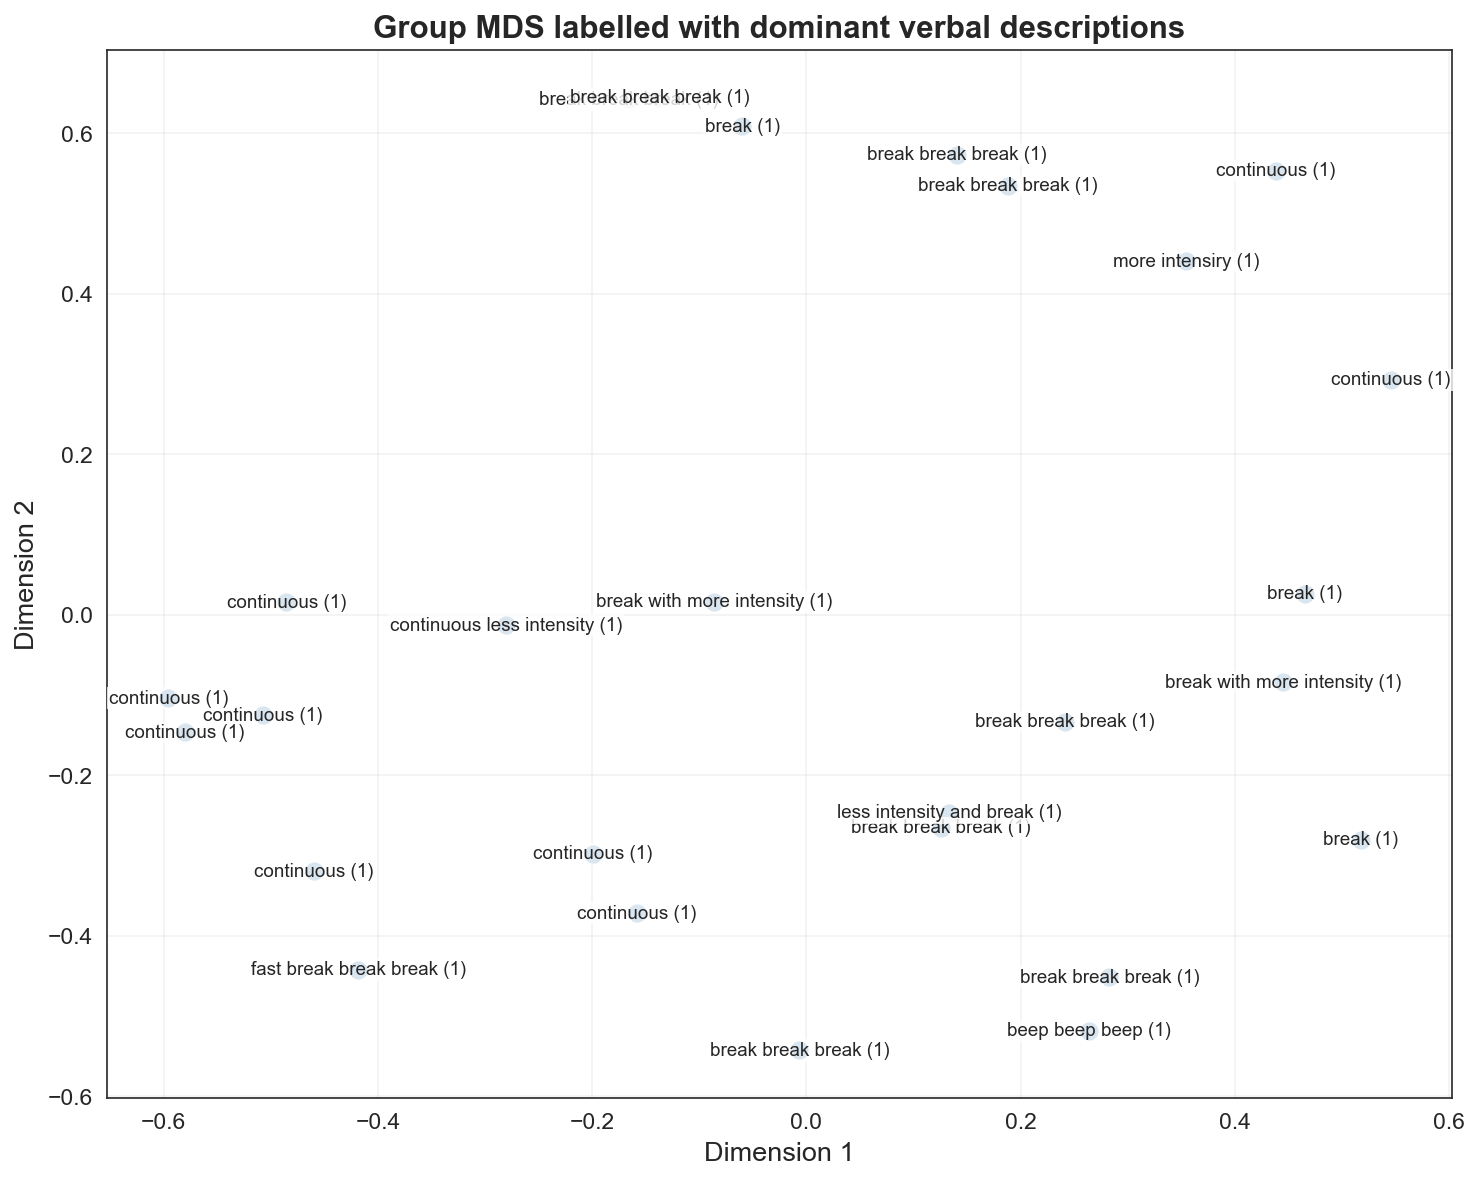

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

# Scatter points
plt.scatter(
    coords[:,0],
    coords[:,1],
    s=60,
    color="steelblue"
)

# Add verbal labels
for i, (x, y) in enumerate(coords):

    plt.text(
        x,
        y,
        labels.loc[i, "Label"],
        fontsize=9,
        ha="center",
        va="center",
        bbox=dict(
            facecolor="white",
            alpha=0.8,
            edgecolor="none",
            pad=1
        )
    )

plt.xlabel("Dimension 1", fontsize=13)
plt.ylabel("Dimension 2", fontsize=13)

plt.title(
    "Group MDS labelled with dominant verbal descriptions",
    fontsize=15,
    fontweight="bold"
)

plt.grid(alpha=0.25)

plt.tight_layout()

plt.show()

In [48]:
import matplotlib.pyplot as plt

participants = verbal["Participant"].unique()

fig, axes = plt.subplots(2,3,figsize=(18,12))

axes = axes.flatten()

for ax, pid in zip(axes, participants):

    coords = participant_coords[pid]

    labels = (
        verbal[verbal["Participant"]==pid]
        .sort_values("Presentation_Order")
        ["Description"]
        .tolist()
    )

    ax.scatter(coords[:,0],coords[:,1],s=40)

    for (x,y),label in zip(coords,labels):

        ax.text(
            x,
            y,
            label,
            fontsize=8,
            ha="center",
            va="center"
        )

    ax.set_title(pid,fontweight="bold")

plt.tight_layout()

plt.show()

KeyError: 'Participant'

In [49]:
import pandas as pd
import os

participants = [f"CDT_P00{i}" for i in range(1,7)]

verbal_data = {}

for pid in participants:

    file = f"results/{pid}/{pid}_VD.csv"

    df = pd.read_csv(file)

    verbal_data[pid] = df

    print(pid, df.shape)


FileNotFoundError: [Errno 2] No such file or directory: 'results/CDT_P001/CDT_P001_VD.csv'

In [50]:
import pandas as pd
import os

participants = [f"CDT_P00{i}" for i in range(1,7)]

verbal_data = {}

for pid in participants:

    file = f"../results/{pid}/{pid}_VD.csv"

    df = pd.read_csv(file)

    verbal_data[pid] = df

    print(pid, df.shape)

CDT_P001 (27, 3)
CDT_P002 (27, 3)
CDT_P003 (27, 3)
CDT_P004 (27, 3)
CDT_P005 (27, 3)
CDT_P006 (27, 3)


In [54]:
print(verbal_data["CDT_P001"].columns)
print(globals().keys())


Index(['Presentation_Order', 'Stimulus_File', 'Description'], dtype='str')
dict_keys(['__name__', '__doc__', '__package__', '__loader__', '__spec__', '__builtin__', '__builtins__', '_ih', '_oh', '_dh', 'In', 'Out', 'get_ipython', 'exit', 'quit', 'open', '_', '__', '___', '__vsc_ipynb_file__', '_i', '_ii', '_iii', '_i1', 'os', 'glob', 'np', 'pd', 'plt', 'mlines', 'sns', 'MDS', '_i2', 'RESULTS_DIR', 'participant_dirs', 'participants', 'folder', 'pid', 'matrix', 'response', 'verbal', '_i3', 'waveforms', 'ifis', 'am_depths', 'metadata', 'stim', 'wf', 'ifi', 'am', '_3', '_i4', 'qc', 'data', '_4', '_i5', 'all_matrices', 'group_similarity', '_i6', 'group_dissimilarity', 'group_similarity_df', 'group_dissimilarity_df', '_i7', 'fig', 'ax', '_i8', '_i9', 'axes', 'diss', '_i10', 'analysis_matrices', 'nan_mask', '_i11', 'mds_results', 'name', 'mds', 'coords', '_i12', 'stress_table', '_12', '_i13', 'Line2D', 'plot_mds', '_i14', 'datasets', 'titles', 'r', '_i15', 'stress_df', '_15', '_i16', 'pdist',

TypeError: unhashable type: 'slice'

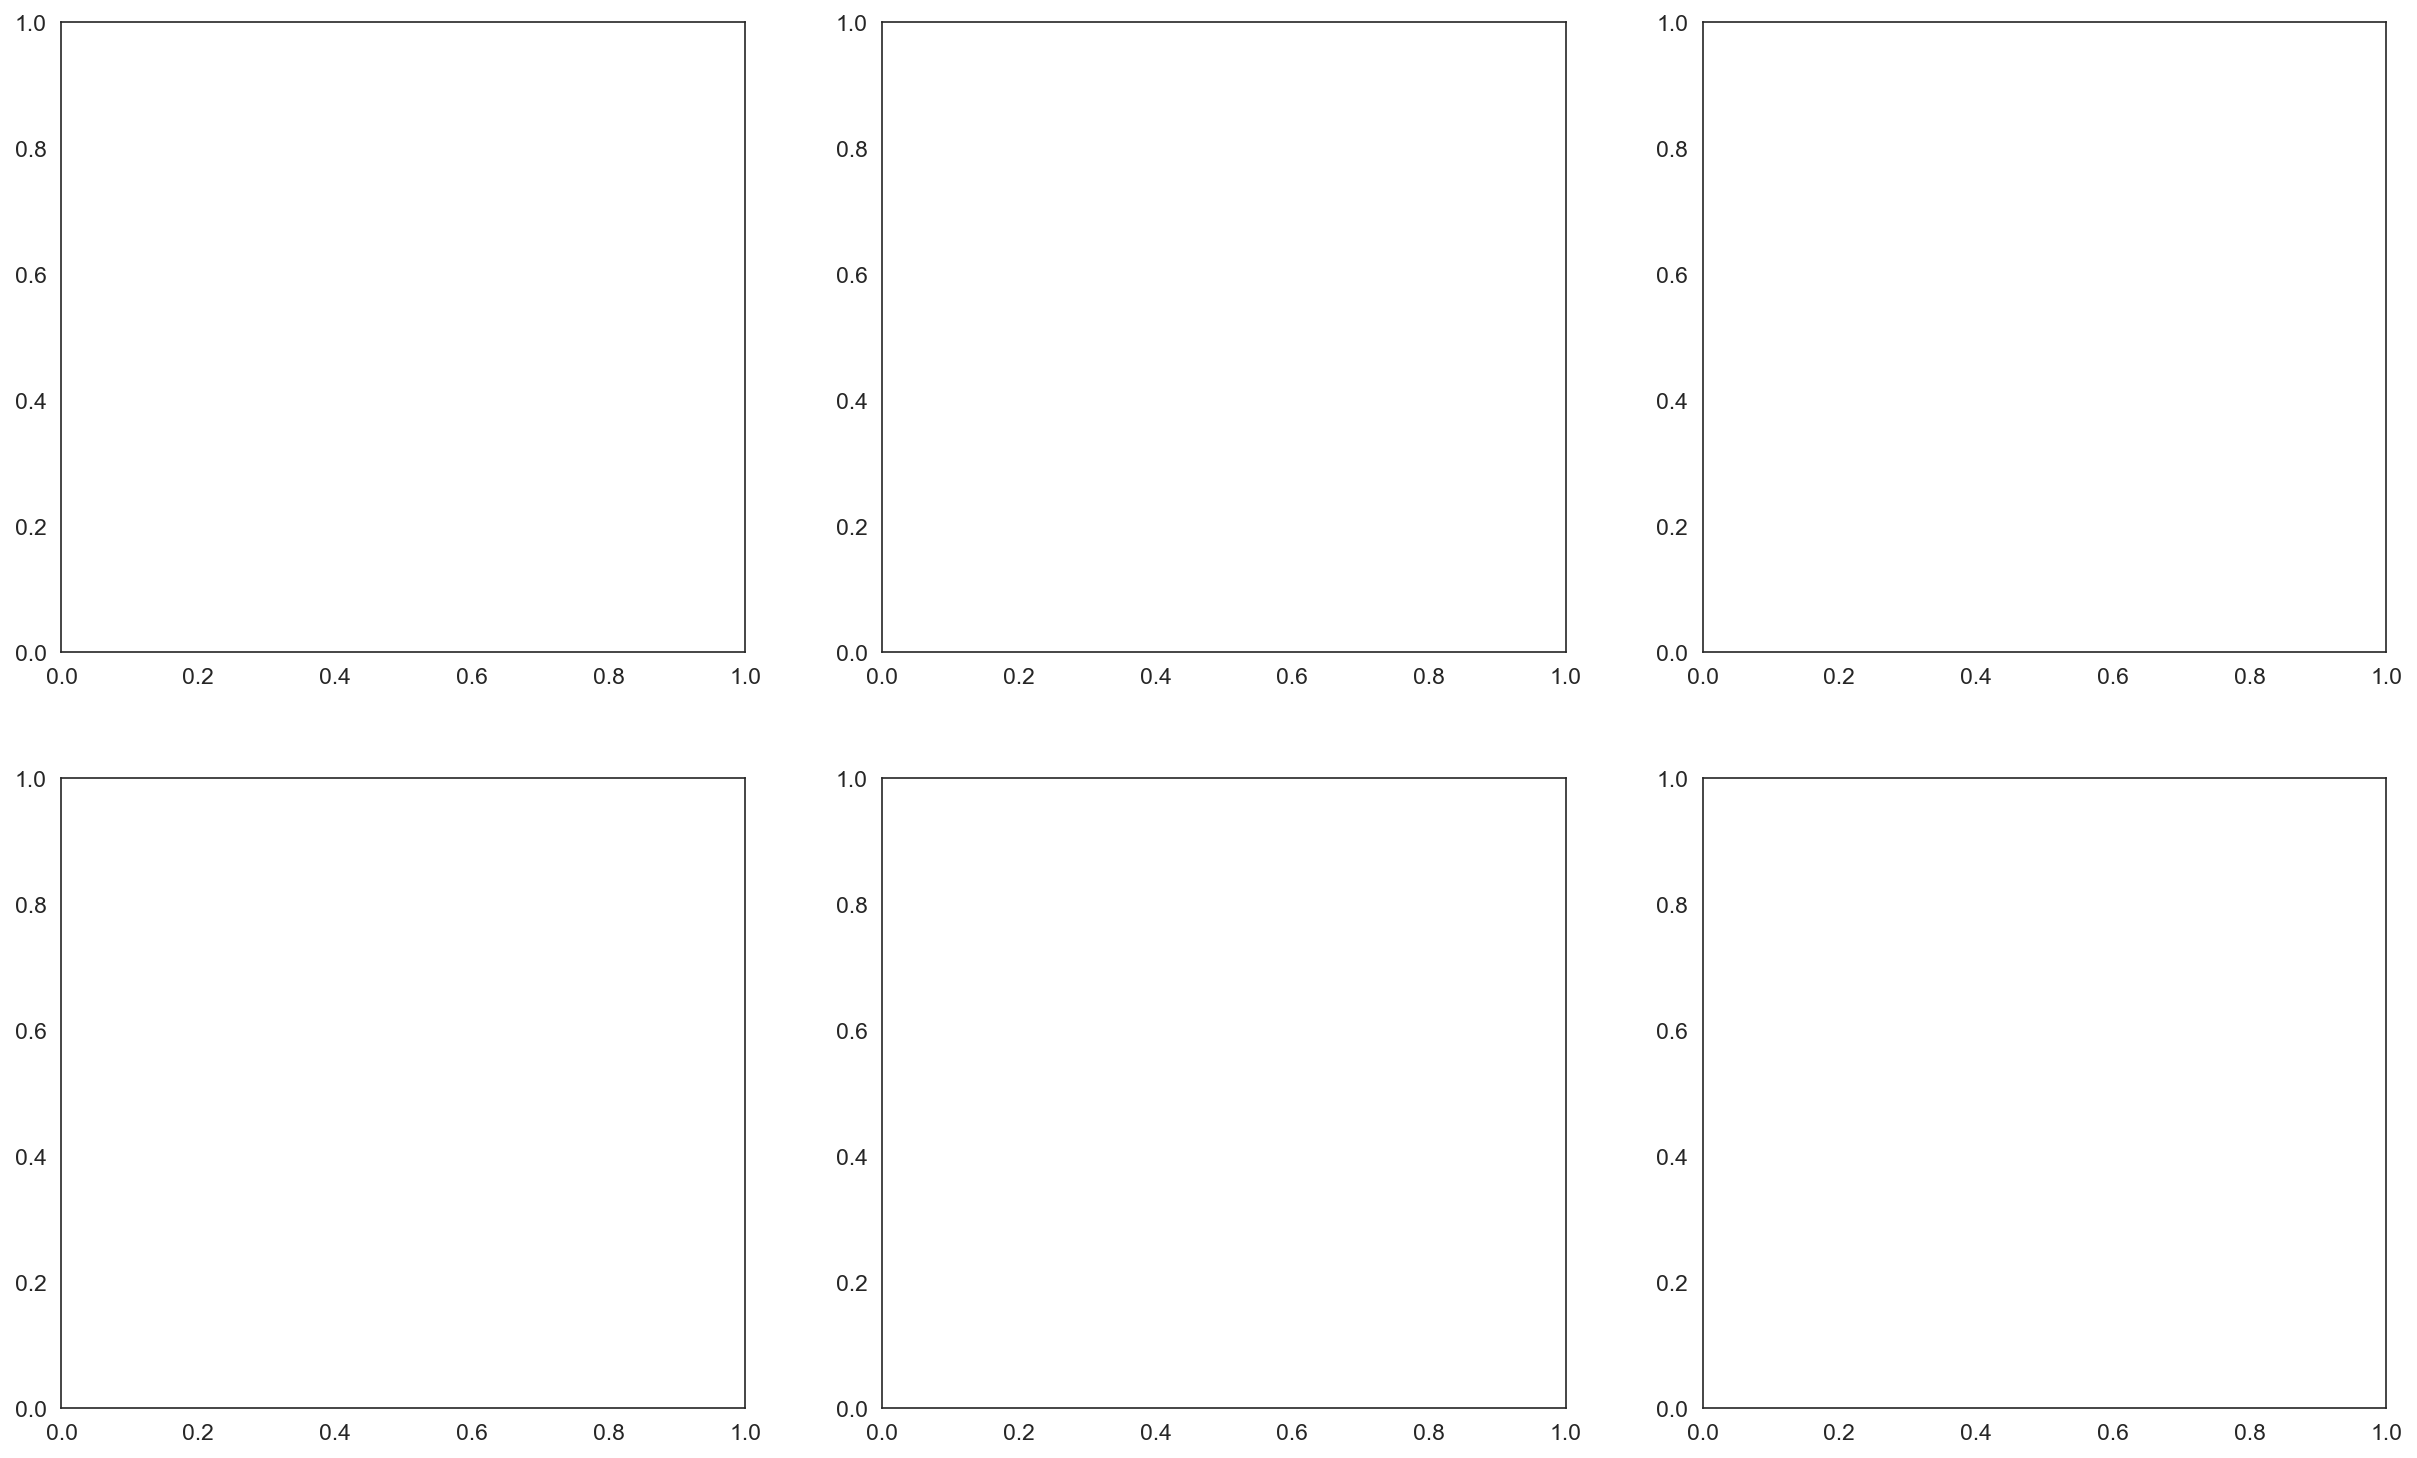

In [55]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for ax, pid in zip(axes, participants):

    # MDS coordinates
    coords = mds_results[pid]

    # verbal descriptions
    labels = (
        verbal_data[pid]
        .sort_values("Presentation_Order")["Description"]
        .astype(str)
        .tolist()
    )

    ax.scatter(
        coords[:,0],
        coords[:,1],
        s=45,
        color="steelblue"
    )

    for (x, y), label in zip(coords, labels):

        ax.text(
            x,
            y,
            label,
            fontsize=8,
            ha="center",
            va="center"
        )

    ax.set_title(pid, fontsize=13, fontweight="bold")

    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

plt.tight_layout()
plt.show()

In [56]:
print(type(mds_results["CDT_P001"]))
print(mds_results["CDT_P001"])

<class 'dict'>
{'coords': array([[ 0.3147814 , -0.08926306],
       [ 0.08906522, -0.25822903],
       [-0.273604  , -0.25076158],
       [ 0.3194501 ,  0.14305478],
       [-0.17777205, -0.01426324],
       [-0.20081759,  0.03552057],
       [ 0.41166416,  0.07937386],
       [-0.15105962,  0.19958868],
       [-0.27225509,  0.27863161],
       [ 0.28575745, -0.23915294],
       [-0.030515  , -0.3410728 ],
       [-0.2354276 , -0.24147349],
       [ 0.30622437,  0.28298616],
       [-0.14936088,  0.10196152],
       [-0.24217147,  0.00835671],
       [ 0.36279717,  0.25198034],
       [-0.11132544,  0.12801886],
       [-0.21874345,  0.05793136],
       [ 0.34497657, -0.17526658],
       [-0.06405578, -0.20677315],
       [-0.21028187, -0.15814367],
       [ 0.147834  ,  0.15242172],
       [-0.08333539,  0.05105726],
       [-0.17589884,  0.03818975],
       [ 0.50387941,  0.16154559],
       [-0.22741875, -0.00950539],
       [-0.26238702,  0.01328613]]), 'stress': np.float64(53.026

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

participants = [f"CDT_P00{i}" for i in range(1,7)]

verbal_data = {}

for pid in participants:

    file = f"../results/{pid}/{pid}_VD.csv"

    verbal_data[pid] = pd.read_csv(file)

print("Loaded verbal descriptions for:")
print(list(verbal_data.keys()))

Loaded verbal descriptions for:
['CDT_P001', 'CDT_P002', 'CDT_P003', 'CDT_P004', 'CDT_P005', 'CDT_P006']


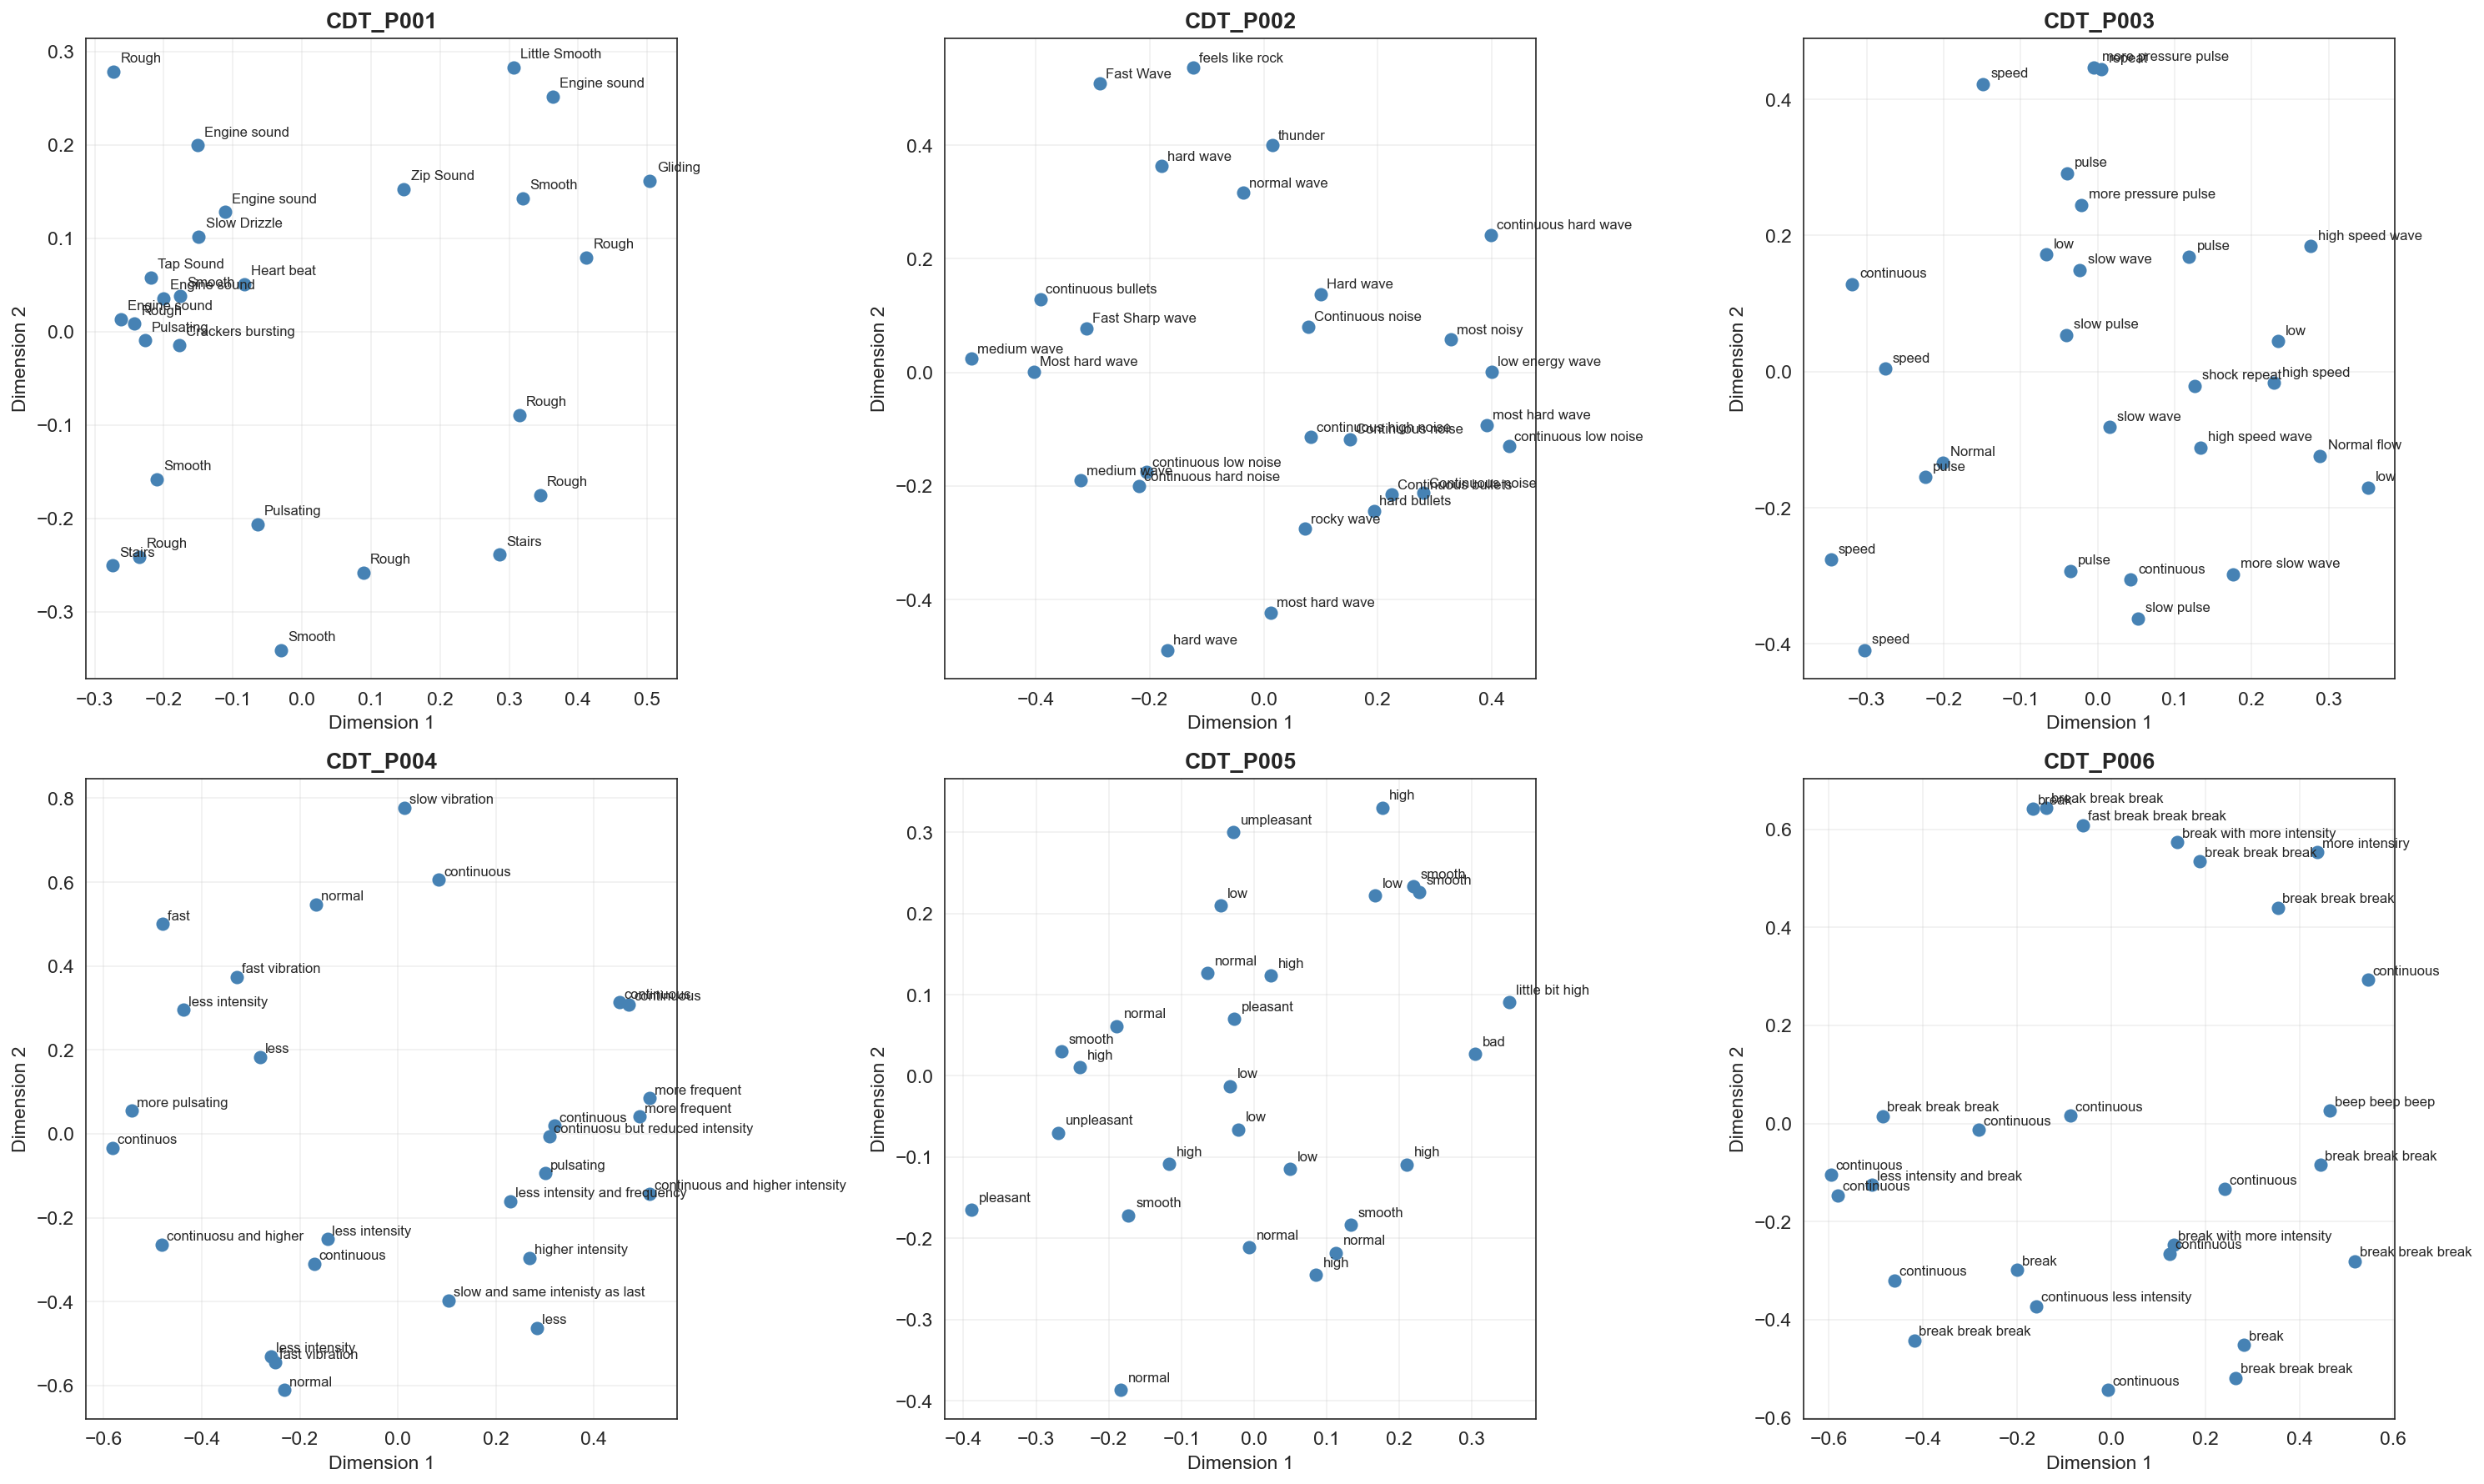

In [58]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for ax, pid in zip(axes, participants):

    # Participant coordinates
    coords = mds_results[pid]["coords"]

    # Participant verbal labels
    labels = (
        verbal_data[pid]
        .sort_values("Presentation_Order")
        ["Description"]
        .astype(str)
        .tolist()
    )

    ax.scatter(
        coords[:,0],
        coords[:,1],
        s=45,
        color="steelblue"
    )

    for (x, y), label in zip(coords, labels):

        ax.text(
            x + 0.01,
            y + 0.01,
            label,
            fontsize=8
        )

    ax.set_title(pid, fontsize=13, fontweight="bold")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

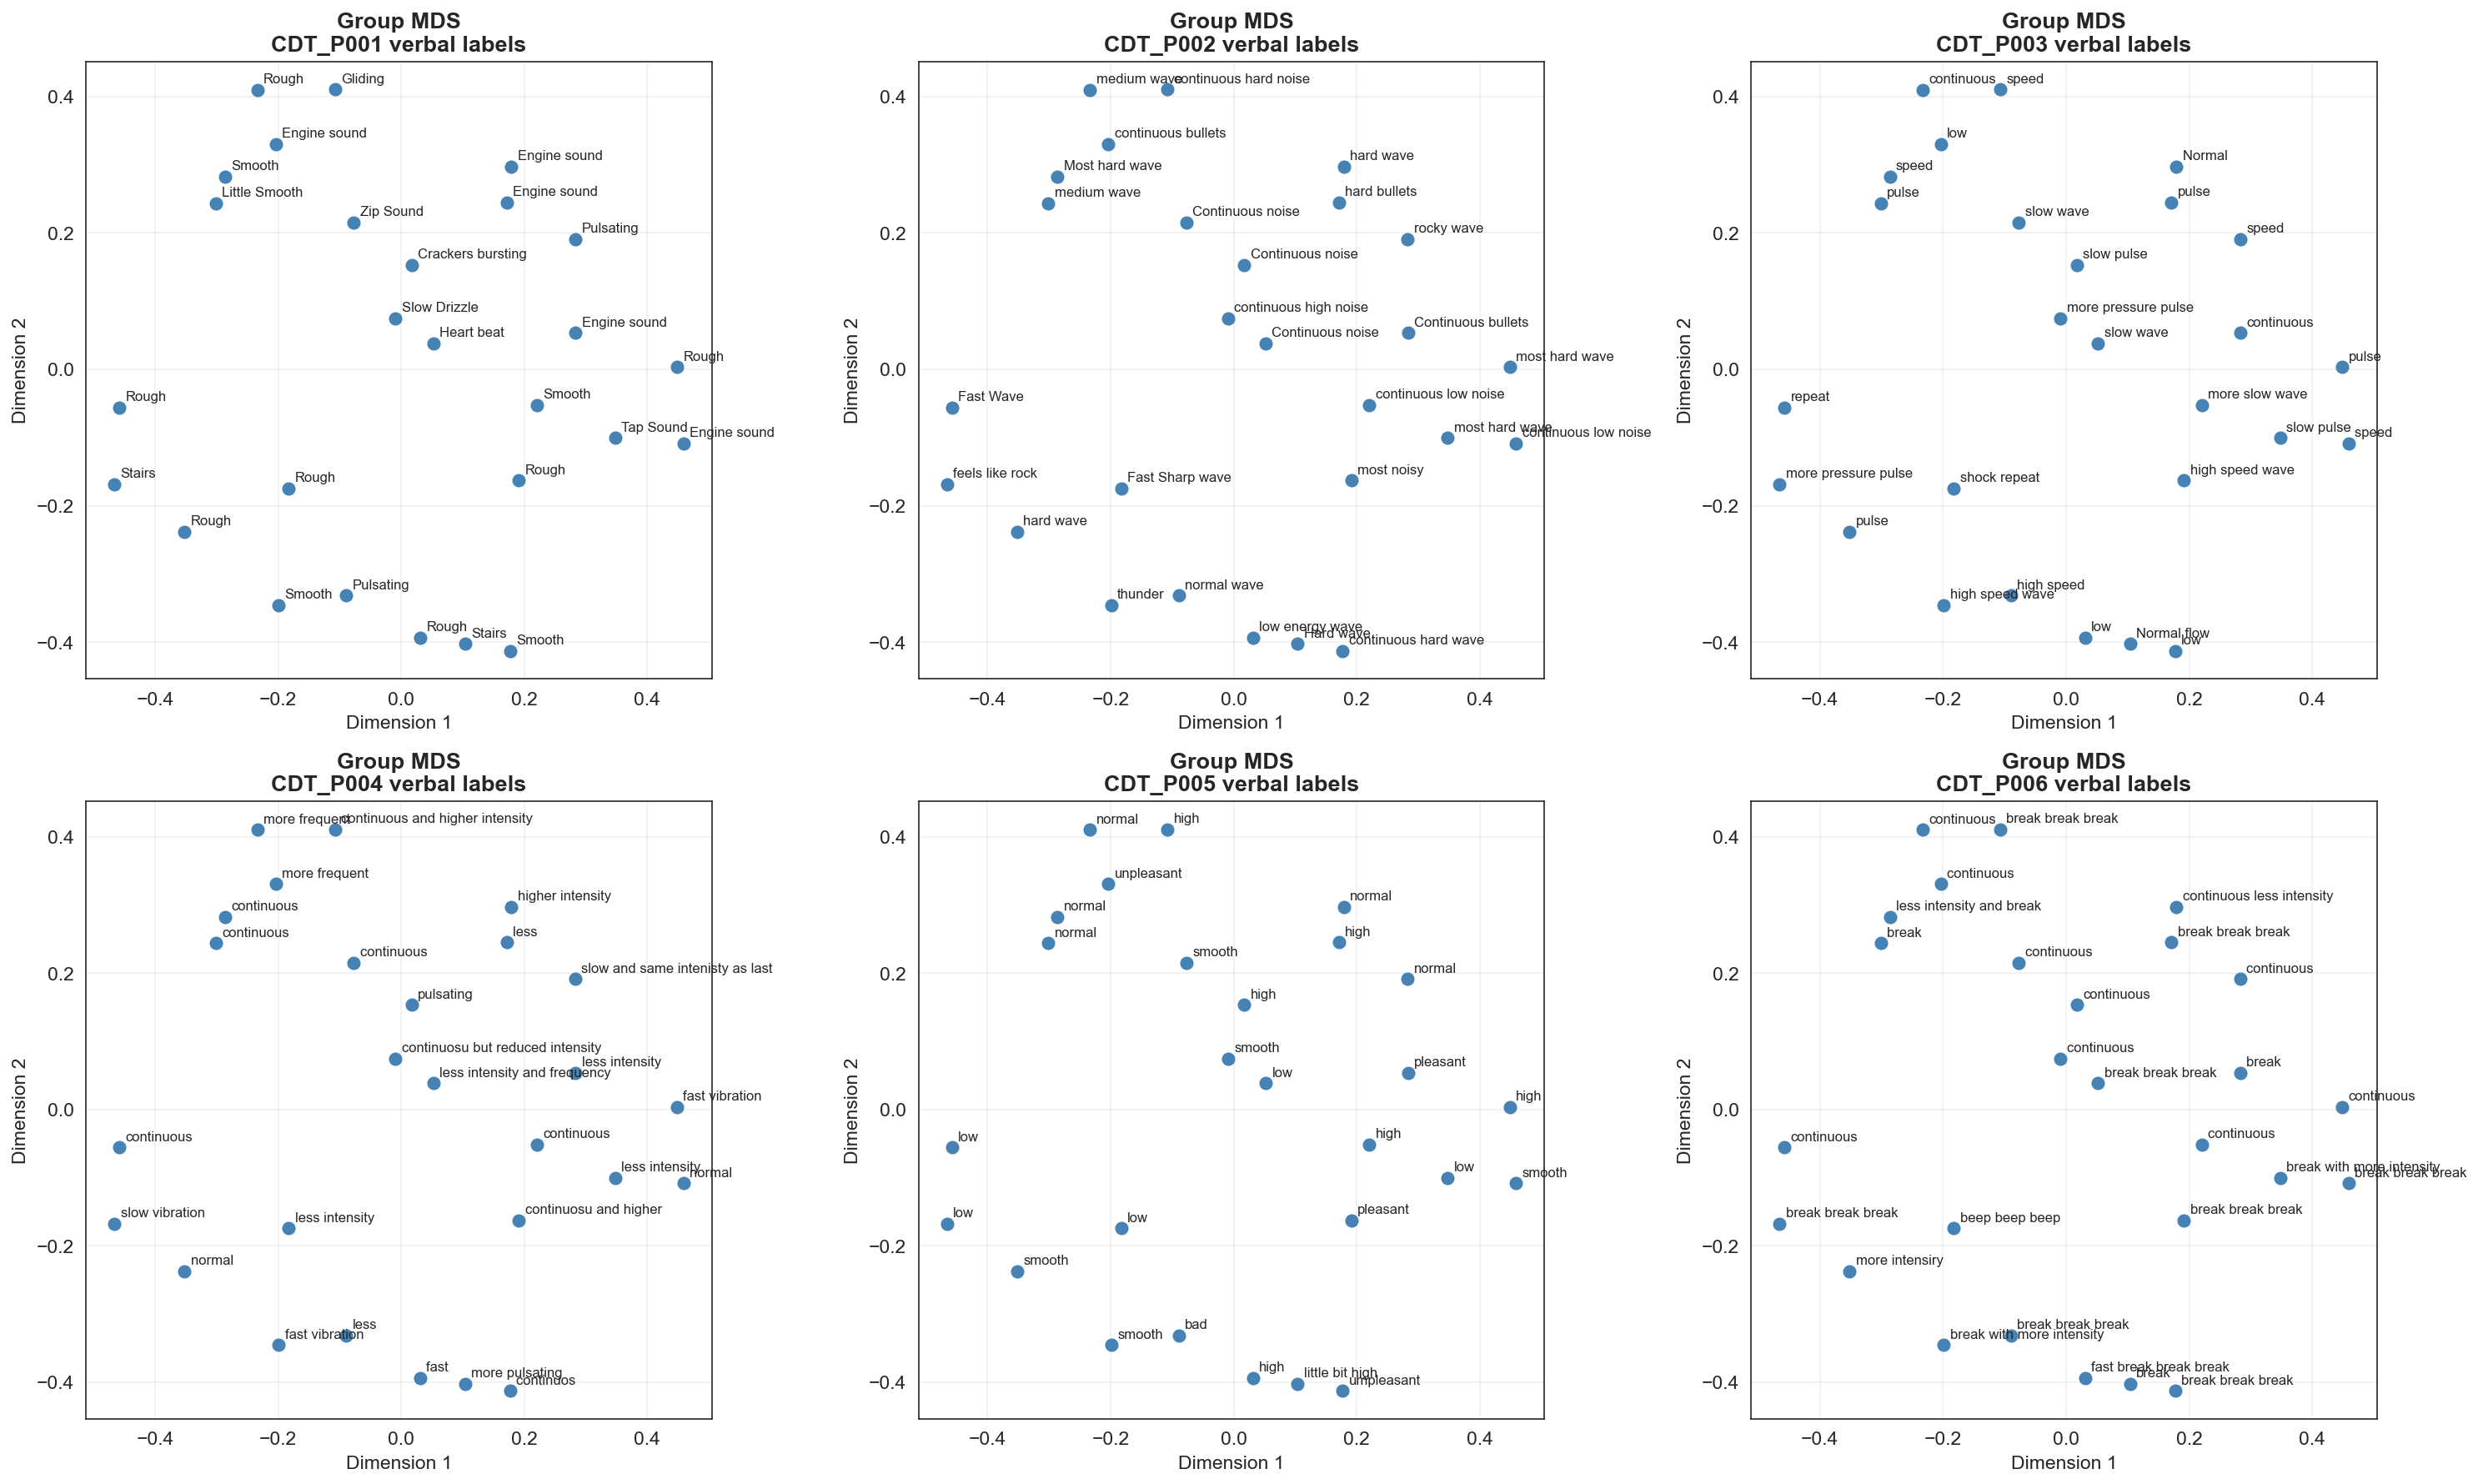

In [59]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for ax, pid in zip(axes, participants):

    labels = (
        verbal_data[pid]
        .sort_values("Presentation_Order")
        ["Description"]
        .astype(str)
        .tolist()
    )

    ax.scatter(
        group_coords[:,0],
        group_coords[:,1],
        s=45,
        color="steelblue"
    )

    for (x, y), label in zip(group_coords, labels):

        ax.text(
            x + 0.01,
            y + 0.01,
            label,
            fontsize=8
        )

    ax.set_title(
        f"Group MDS\n{pid} verbal labels",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()